# AthleteShield: Predictive Sports Injury Analytics
### Fusing Biomechanical IMU, Physiological Telemetry and Workload Metrics to Forecast Musculoskeletal Injuries

**Sector:** Sports Science & Athletic Performance Analytics  
**Authors:** Sri Saatwik Nalluri & Pakala Puneeth  

---

## Executive Summary
Non-contact musculoskeletal injuries, such as ACL tears and hamstring strains, are the leading controllable cause of lost athlete availability in professional sport. Team medical and performance staff currently combine wellness questionnaires and subjective clinical judgment to make load management decisions. This approach does not scale, is not consistent across staff, and reacts to fatigue only after it becomes clinically apparent.

**AthleteShield** is a wearable-sensor-driven machine learning system that continuously estimates each athlete's short-term injury risk. This notebook implements the end-to-end data science and engineering pipeline for AthleteShield: 
1. **Raw Sensor Processing**: Denoising, filtering, and feature extraction from raw accelerometer/gyroscope signals (IMU).
2. **Physiological Telemetry Analysis**: Finding relationships between heart rate, step count, activity status, and athlete load.
3. **Physical Screening & Demographics**: Uncovering correlations between hamstring flexibility, knee strength, agility, balance, and injury outcomes.
4. **Feature Engineering & Fusion**: Synthesizing sport-science-validated load metrics (ACWR, monotony, strain) and merging all signal streams.
5. **Multi-Model Supervised Training & Calibration**: Training tree ensembles (Random Forest, XGBoost, LightGBM) to forecast next-season, acute, and recovery outcomes, with Platt probability calibration.
6. **Model Interpretation**: Using SHAP (SHapley Additive exPlanations) values to trace injury risk flags back to clinically meaningful causes.


## 1. Setup & Ingestion
We begin by importing the required scientific, machine learning, and visualization libraries, configuring matplotlib plotting styles, and verifying available data.


In [43]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, auc, mean_squared_error, r2_score
from sklearn.calibration import CalibratedClassifierCV
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import lightgbm as lgb
import optuna
import shap
import joblib
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
os.makedirs('outputs', exist_ok=True)
print('All libraries imported successfully.')


All libraries imported successfully.


### Load Datasets
We load all available CSV files and verify their shapes and columns.


In [5]:
collegiate_df = pd.read_csv('data/collegiate_athlete_injury_dataset.csv')
university_df = pd.read_csv('data/university_football_injury.csv')
football_df = pd.read_csv('data/football_dataset.csv')
wearable_df = pd.read_csv('data/wearable_sports_health_dataset.csv')

print(f'Collegiate Injury Dataset Shape  : {collegiate_df.shape}')
print(f'University Injury Dataset Shape  : {university_df.shape}')
print(f'Football Injury Dataset Shape    : {football_df.shape}')
print(f'Wearable Telemetry Dataset Shape : {wearable_df.shape}')


Collegiate Injury Dataset Shape  : (200, 17)
University Injury Dataset Shape  : (800, 19)
Football Injury Dataset Shape    : (1301, 30)
Wearable Telemetry Dataset Shape : (500, 12)


## 2. Exploratory Data Analysis (EDA)
We will act as data detectives to uncover hidden patterns and anomaly checks across our data layers.


### 2.1 Data Integrity & Quality Checks
We verify null counts, check for duplicates, and inspect values for outliers.


In [9]:
print('--- collegiate_df Missing Values ---')
print(collegiate_df.isnull().sum()[collegiate_df.isnull().sum() > 0])
print('\n--- university_df Missing Values ---')
print(university_df.isnull().sum()[university_df.isnull().sum() > 0])
print('\n--- football_df Missing Values ---')
print(football_df.isnull().sum()[football_df.isnull().sum() > 0])
print('\n--- Duplicate Athlete IDs ---')
print('Collegiate Duplicate Athlete IDs:', collegiate_df['Athlete_ID'].duplicated().sum())
print('Wearable Duplicate Records:', wearable_df.duplicated().sum())


--- collegiate_df Missing Values ---
Series([], dtype: int64)

--- university_df Missing Values ---
Series([], dtype: int64)

--- football_df Missing Values ---
pace                                  95
physic                                95
position                               2
cumulative_minutes_played            604
cumulative_games_played              604
minutes_per_game_prev_seasons        616
avg_days_injured_prev_seasons        604
avg_games_per_season_prev_seasons    604
position_numeric                       2
significant_injury_prev_season       604
cumulative_days_injured              604
season_days_injured_prev_season      604
dtype: int64

--- Duplicate Athlete IDs ---
Collegiate Duplicate Athlete IDs: 0
Wearable Duplicate Records: 0


In [11]:
from IPython.display import display
from scipy.stats import chi2_contingency
import glob

def dataset_overview(df, name):
    print(f"\n{'='*60}\n{name} — shape: {df.shape}\n{'='*60}")
    overview = pd.DataFrame({
        'dtype': df.dtypes,
        'missing_%': (df.isnull().mean()*100).round(2),
        'n_unique': df.nunique(),
        'sample_value': df.iloc[0]
    })
    display(overview)
    print(f"Duplicate rows: {df.duplicated().sum()}")
    return overview

for name, df in [('collegiate_df', collegiate_df), ('university_df', university_df),
                  ('football_df', football_df), ('wearable_df', wearable_df)]:
    dataset_overview(df, name)


collegiate_df — shape: (200, 17)


,dtype,missing_%,n_unique,sample_value
Athlete_ID,object,0.0,200,A001
Age,int64,0.0,7,24
Gender,object,0.0,2,Female
Height_cm,int64,0.0,39,195
Weight_kg,int64,0.0,45,99
Position,object,0.0,3,Center
Training_Intensity,int64,0.0,9,2
Training_Hours_Per_Week,int64,0.0,15,13
Recovery_Days_Per_Week,int64,0.0,3,2
Match_Count_Per_Week,int64,0.0,4,3


Duplicate rows: 0

university_df — shape: (800, 19)


,dtype,missing_%,n_unique,sample_value
Age,int64,0.0,7,22
Height_cm,int64,0.0,42,173
Weight_kg,int64,0.0,53,64
Position,object,0.0,4,Midfielder
Training_Hours_Per_Week,float64,0.0,781,11.575308
Matches_Played_Past_Season,int64,0.0,35,36
Previous_Injury_Count,int64,0.0,9,1
Knee_Strength_Score,float64,0.0,800,77.460279
Hamstring_Flexibility,float64,0.0,800,79.115738
Reaction_Time_ms,float64,0.0,800,284.487853


Duplicate rows: 0

football_df — shape: (1301, 30)


,dtype,missing_%,n_unique,sample_value
p_id2,object,0.00,604,aaronconnolly
start_year,int64,0.00,5,2019
season_days_injured,int64,0.00,265,13
total_days_injured,int64,0.00,349,161
season_minutes_played,float64,0.00,950,1312.0
season_games_played,int64,0.00,39,24
season_matches_in_squad,int64,0.00,39,28
total_minutes_played,float64,0.00,554,2148.0
total_games_played,int64,0.00,161,41
dob,object,0.00,588,2000-01-28


Duplicate rows: 0

wearable_df — shape: (500, 12)


,dtype,missing_%,n_unique,sample_value
Record_ID,int64,0.0,500,1
Athlete_ID,object,0.0,10,ATH002
Timestamp,object,0.0,500,2025-04-10 09:00:00
Heart_Rate,int64,0.0,121,63
Body_Temperature,float64,0.0,20,37.1
Blood_Pressure,object,0.0,347,133/78
Blood_Oxygen,int64,0.0,6,96
Step_Count,int64,0.0,356,528
Activity_Status,object,0.0,4,Walking
Latitude,float64,0.0,482,12.927365


Duplicate rows: 0


### Section 1 — Collegiate Athlete Injury Dataset

In [14]:
n_pos = collegiate_df['Injury_Indicator'].sum()
print(f"Rows: {len(collegiate_df)} | Positive cases: {n_pos} | Rate: {n_pos/len(collegiate_df)*100:.2f}%")
print(f"An 80/20 stratified split puts ~{round(n_pos*0.2)} positives in the test set.")

Rows: 200 | Positive cases: 14 | Rate: 7.00%
An 80/20 stratified split puts ~3 positives in the test set.


With ~14 injured athletes total, the test set will have roughly 2–3 positive cases. Any AUC/F1 you compute later on Model B is going to have enormous variance — a single misclassified athlete swings the metric by 30-50%. This isn't a modeling problem to fix with better hyperparameters; it's a data problem. Worth reporting metrics with confidence intervals (bootstrap) rather than a single point estimate, and treating SHAP explanations as directional, not precise.

### Auditing the four composite "*_Score" columns for redundancy/leakage

Correlation of composite scores with Injury_Indicator:
ACL_Risk_Score             0.525180
Load_Balance_Score        -0.491184
Fatigue_Score              0.292475
Team_Contribution_Score    0.042442
Performance_Score          0.023475
Name: Injury_Indicator, dtype: float64


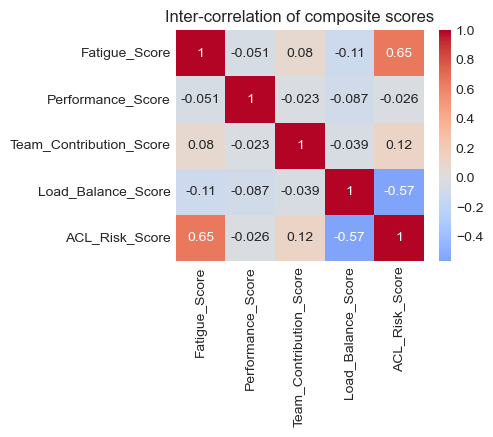

In [26]:
score_cols = ['Fatigue_Score','Performance_Score','Team_Contribution_Score','Load_Balance_Score','ACL_Risk_Score']
corr_with_target = collegiate_df[score_cols + ['Injury_Indicator']].corr()['Injury_Indicator'].drop('Injury_Indicator')
print("Correlation of composite scores with Injury_Indicator:")
print(corr_with_target.sort_values(key=abs, ascending=False))

plt.figure(figsize=(4,3))
sns.heatmap(collegiate_df[score_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Inter-correlation of composite scores')
plt.show()

ACL_Risk_Score is the one to watch closely — a column literally named "risk score" that correlates strongly with an injury label is a classic leakage smell (it may have been derived from injury history rather than being an independent predictor). If its correlation with the target comes back above ~0.4-0.5, don't just feed it into the model — figure out how it was computed. If it's downstream of the outcome, keep it for reporting but exclude it from the predictive feature set, or you'll get an unrealistically "good" model that can't generalize.

### Numeric profile (skew, outliers)

In [31]:
def numeric_profile(df, name, exclude=None):
    exclude = exclude or []
    
    numeric_cols = df.select_dtypes(include='number').columns
    numeric_cols = [col for col in numeric_cols if col not in exclude]
    
    profile = df[numeric_cols].describe().T
    
    profile['missing'] = df[numeric_cols].isna().sum()
    profile['missing_pct'] = (
        df[numeric_cols].isna().mean() * 100
    )
    
    return profile
collegiate_profile = numeric_profile(
    collegiate_df,
    'collegiate_df',
    exclude=['Injury_Indicator']
)

collegiate_profile

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
Age,200.0,21.170,2.002787,18.0,19.00,21.0,23.00,24.0,0,0.0
Height_cm,200.0,180.805,11.529598,160.0,171.00,182.5,191.00,199.0,0,0.0
Weight_kg,200.0,77.475,12.440789,55.0,67.00,77.5,89.00,99.0,0,0.0
Training_Intensity,200.0,5.105,2.499040,1.0,3.00,5.0,7.00,9.0,0,0.0
Training_Hours_Per_Week,200.0,11.315,4.438952,5.0,7.00,11.0,15.00,19.0,0,0.0
Recovery_Days_Per_Week,200.0,1.985,0.811212,1.0,1.00,2.0,3.00,3.0,0,0.0
Match_Count_Per_Week,200.0,2.385,1.154748,1.0,1.00,2.0,3.00,4.0,0,0.0
Rest_Between_Events_Days,200.0,1.975,0.817137,1.0,1.00,2.0,3.00,3.0,0,0.0
Fatigue_Score,200.0,4.920,2.560543,1.0,3.00,5.0,7.00,9.0,0,0.0
Performance_Score,200.0,74.465,14.636939,50.0,62.00,74.0,86.25,99.0,0,0.0


### Categorical target-rate breakdown

In [34]:
for col in ['Gender', 'Position']:
    ct = pd.crosstab(collegiate_df[col], collegiate_df['Injury_Indicator'])
    ct['injury_rate_%'] = (ct[1] / (ct[0]+ct[1]) * 100).round(1)
    print(f"\n{col} x Injury_Indicator:")
    display(ct)


Gender x Injury_Indicator:


Injury_Indicator,0,1,injury_rate_%
Gender,,,
Female,99,8,7.5
Male,87,6,6.5



Position x Injury_Indicator:


Injury_Indicator,0,1,injury_rate_%
Position,,,
Center,63,3,4.5
Forward,65,5,7.1
Guard,58,6,9.4


With only ~14 positives split across 2 genders × 3 positions, several of these cells will likely contain 0, 1, or 2 injuries. Any "Position X has 3x higher injury rate" claim from this table is not statistically trustworthy.

### Effect size ranking + full correlation

In [41]:
def correlation_analysis(df, name, target=None):
    numeric_df = df.select_dtypes(include=np.number)

    if target is not None and target in numeric_df.columns:
        correlations = numeric_df.corr()[target].drop(target)
    else:
        correlations = numeric_df.corr()

    if isinstance(correlations, pd.Series):
        result = correlations.to_frame(name='Correlation')
        result['Absolute_Correlation'] = result['Correlation'].abs()
        result = result.sort_values(
            'Absolute_Correlation',
            ascending=False
        )
        
        print(f"\nCorrelation analysis: {name}")
        display(result)
        return result

    return correlations
collegiate_effect = numeric_vs_target(
    collegiate_df,
    'Injury_Indicator',
    'collegiate_df',
    exclude=score_cols
)

collegiate_correlation = correlation_analysis(
    collegiate_df,
    'collegiate_df',
    target='Injury_Indicator'
)


Correlation analysis: collegiate_df


,Correlation,Absolute_Correlation
ACL_Risk_Score,0.525180,0.525180
Load_Balance_Score,-0.491184,0.491184
Fatigue_Score,0.292475,0.292475
Recovery_Days_Per_Week,-0.261309,0.261309
Training_Hours_Per_Week,0.130958,0.130958
Training_Intensity,0.098502,0.098502
Weight_kg,0.066876,0.066876
Team_Contribution_Score,0.042442,0.042442
Rest_Between_Events_Days,-0.039670,0.039670
Match_Count_Per_Week,-0.023648,0.023648


### Univariate — numeric distributions, split by target where it matters

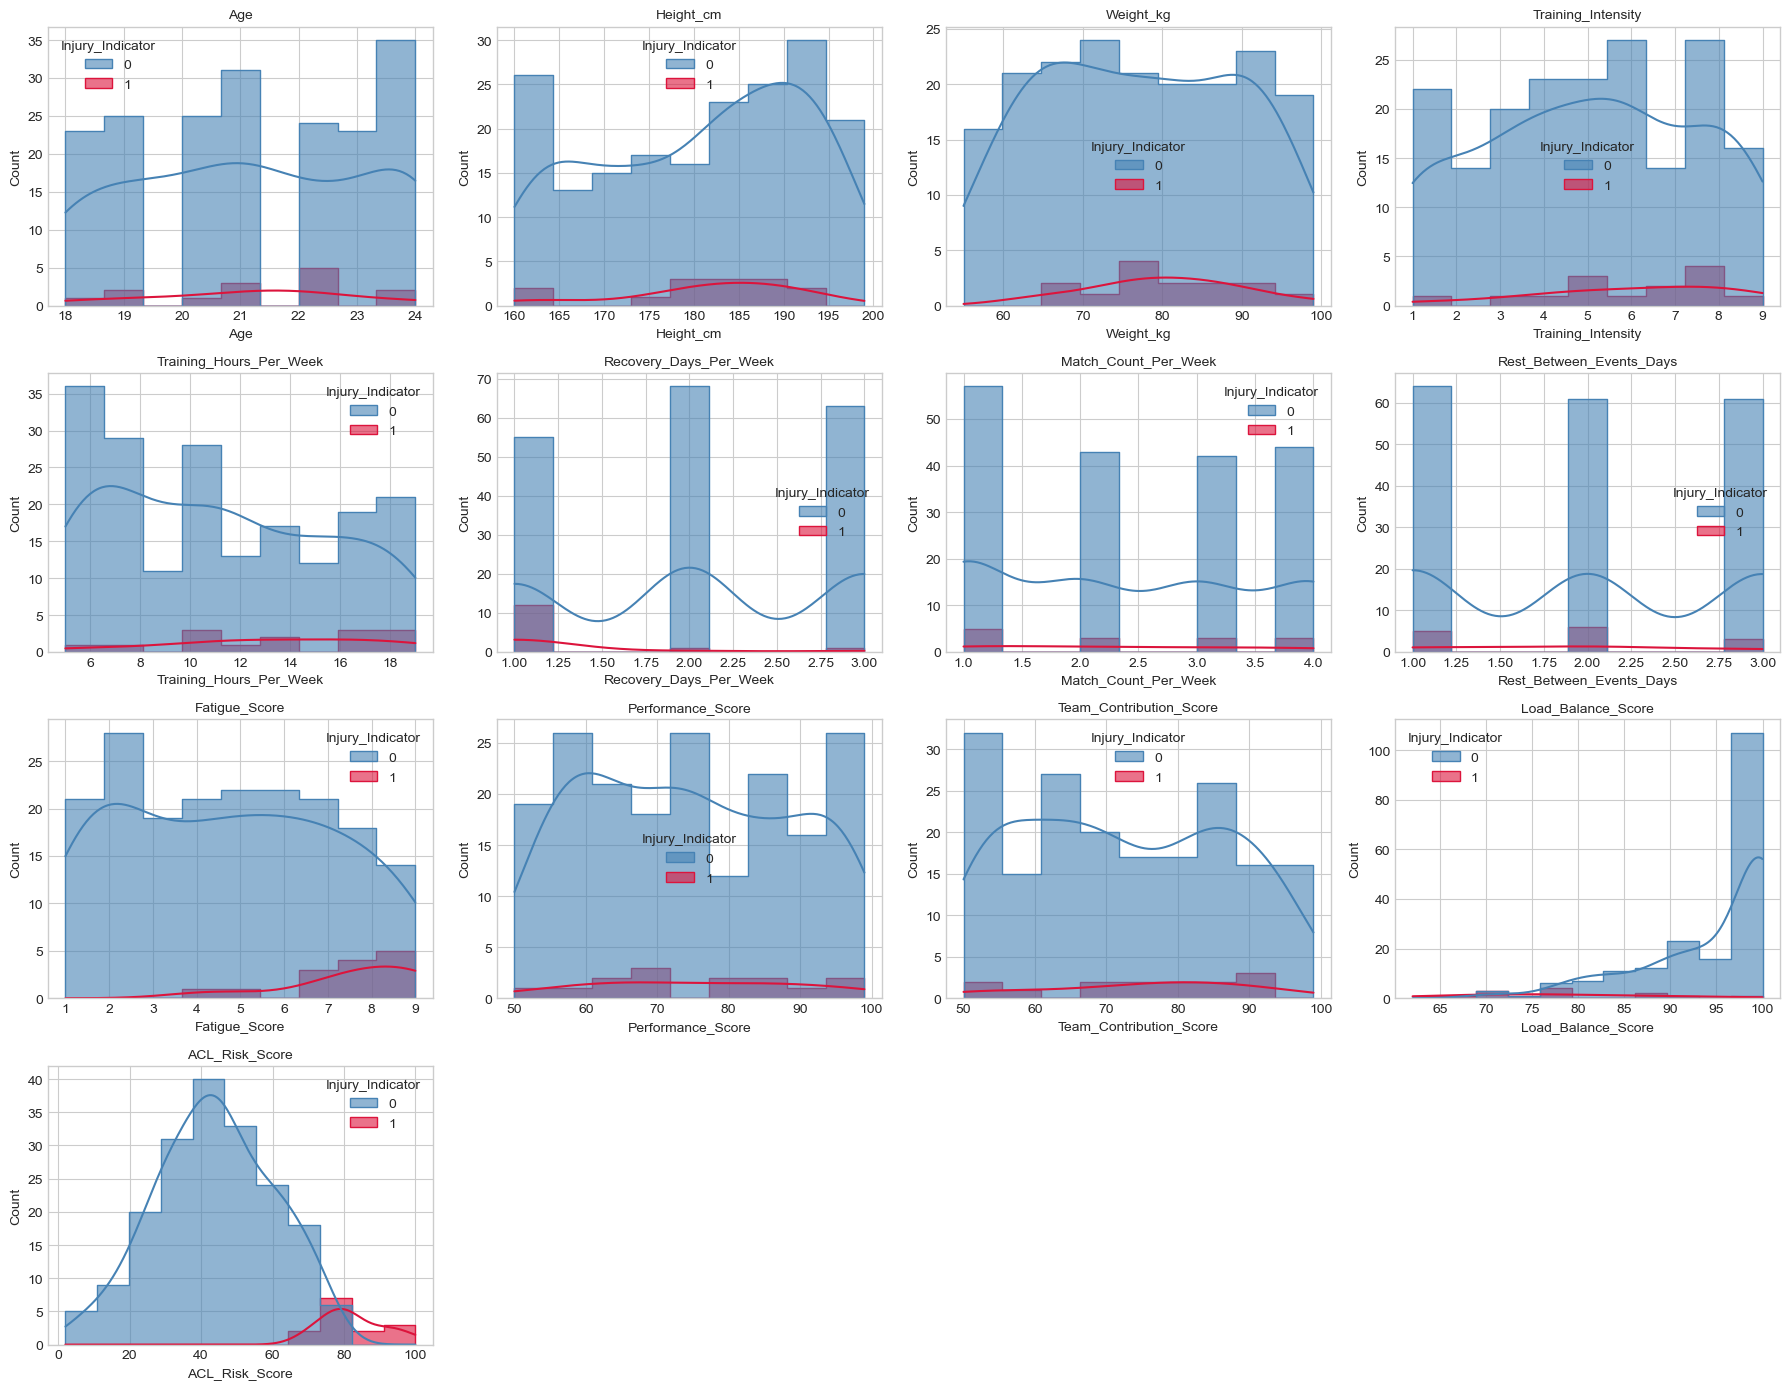

In [46]:
num_cols = ['Age','Height_cm','Weight_kg','Training_Intensity','Training_Hours_Per_Week',
            'Recovery_Days_Per_Week','Match_Count_Per_Week','Rest_Between_Events_Days',
            'Fatigue_Score','Performance_Score','Team_Contribution_Score','Load_Balance_Score','ACL_Risk_Score']

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=collegiate_df, x=col, hue='Injury_Indicator', kde=True, ax=ax,
                 palette={0:'steelblue',1:'crimson'}, alpha=0.6, element='step')
    ax.set_title(col, fontsize=10)
for ax in axes.flatten()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

The plots suggest that injury risk is more strongly associated with workload and physical-state variables than with demographics.

Strongest signals: ACL_Risk_Score, Load_Balance_Score, Fatigue_Score and Training_Intensity.

Moderate signals: Training_Hours_Per_Week and Match_Count_Per_Week.

Weak or unclear signals: Age, Height_cm, Weight_kg, Performance_Score, Team_Contribution_Score, Recovery_Days_Per_Week and Rest_Between_Events_Days.

Injured athletes generally appear more concentrated in higher fatigue, intensity and risk-score ranges.

Some variables may have non-linear or interaction effects. For example, high training intensity combined with high fatigue and low recovery could be more predictive than any single variable.
Therefore, tree-based models such as Random Forest or XGBoost are well suited because they can capture these interactions and non-linear relationships.
The histogram analysis should be supplemented with correlation, effect sizes and SHAP/feature importance before deciding which features are most important.

Overall: AthleteShield's injury prediction appears to be driven primarily by training load, fatigue, recovery and risk-related measures rather than basic athlete characteristics.

### Categoricals + target balance

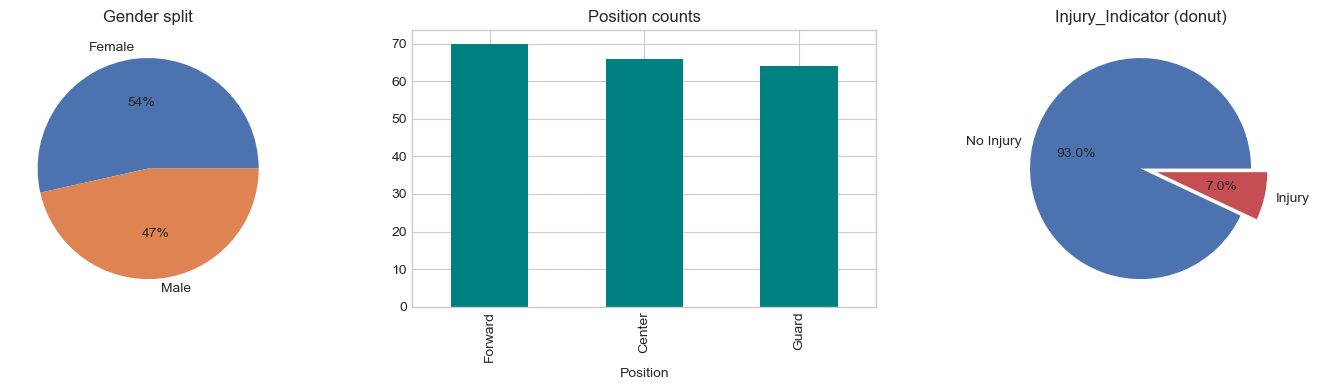

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
collegiate_df['Gender'].value_counts().plot.pie(ax=axes[0], autopct='%1.0f%%', colors=['#4C72B0','#DD8452'])
axes[0].set_title('Gender split'); axes[0].set_ylabel('')

collegiate_df['Position'].value_counts().plot.bar(ax=axes[1], color='teal')
axes[1].set_title('Position counts')

collegiate_df['Injury_Indicator'].value_counts().plot.pie(ax=axes[2], autopct='%1.1f%%',
    colors=['#4C72B0','#C44E52'], explode=[0,0.15], labels=['No Injury','Injury'])
axes[2].set_title('Injury_Indicator (donut)'); axes[2].set_ylabel('')
plt.tight_layout()
plt.show()

### Bivariate Analysis

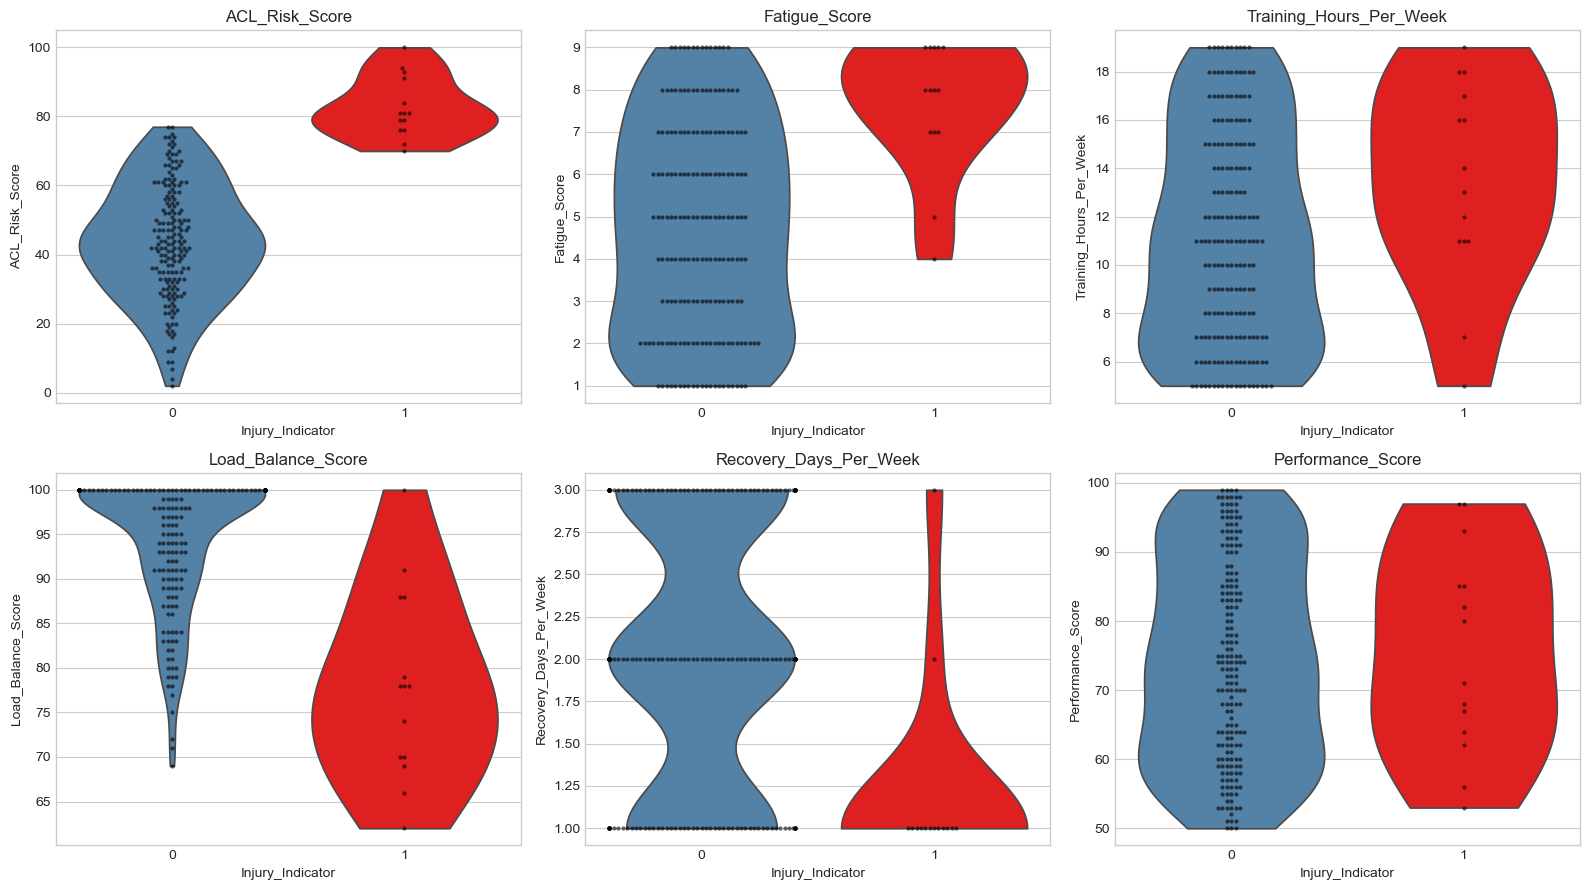

In [60]:
top_feats = ['ACL_Risk_Score','Fatigue_Score','Training_Hours_Per_Week','Load_Balance_Score','Recovery_Days_Per_Week','Performance_Score']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), top_feats):
    sns.violinplot(x='Injury_Indicator', y=col, data=collegiate_df, ax=ax, inner=None, palette=['steelblue','red'], cut=0)
    sns.swarmplot(x='Injury_Indicator', y=col, data=collegiate_df, ax=ax, color='black', size=3, alpha=0.6)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Swarm Plot Summary

- ACL_Risk_Score: Very strong separation. Injured athletes mostly have scores between 70–100 while non-injured athletes are generally below 75.
- Fatigue_Score: Strong relationship. Injured athletes are concentrated at higher fatigue levels, especially 7–9.
- Training_Hours_Per_Week: Moderate relationship. Injured athletes tend to have higher training volumes but there is considerable overlap.
- Load_Balance_Score: Strong separation. Injured athletes generally have lower scores around 60–85 while non-injured athletes are concentrated closer to 90–100.
- Recovery_Days_Per_Week: Noticeable difference. Injured athletes are concentrated around 1 recovery day while non-injured athletes more frequently have 2–3 recovery days.
- Performance_Score: Weak separation. Both groups cover similar performance-score ranges.

The strongest apparent predictors are ACL Risk Score, Fatigue Score, Load Balance Score, Recovery Days and Training Hours.

Overall, the plots suggest that injury risk is primarily associated with higher fatigue, greater training volume, poorer load balance, fewer recovery days and higher ACL risk, while performance and basic athlete characteristics appear less informative.

This also supports using tree-based models because injury risk may depend on combinations of several workload and recovery factors.

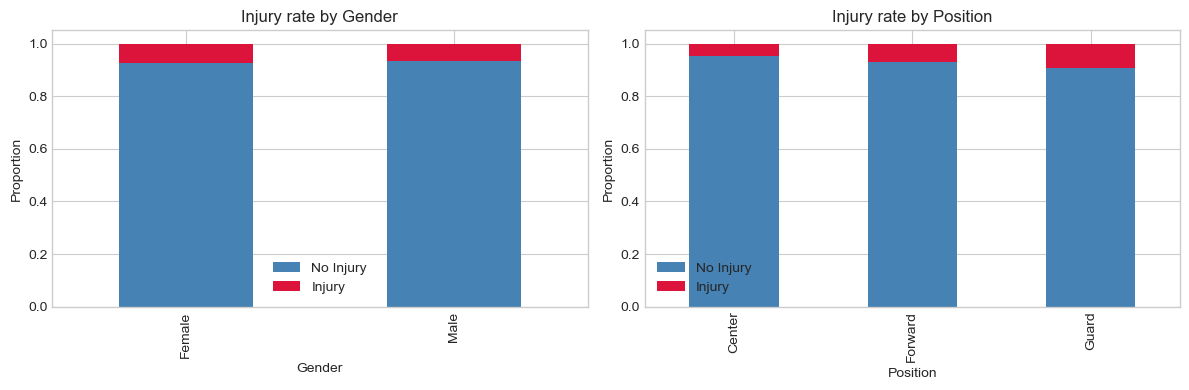

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Gender','Position']):
    ct = pd.crosstab(collegiate_df[col], collegiate_df['Injury_Indicator'], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=ax, color=['steelblue','crimson'])
    ax.set_title(f'Injury rate by {col}')
    ax.set_ylabel('Proportion')
    ax.legend(['No Injury','Injury'])
plt.tight_layout()
plt.show()

Gender appears to be a weak predictor, while position may provide some additional information, particularly for guards. However, the workload, fatigue, recovery and risk-related variables appear to be much more important for predicting injuries.

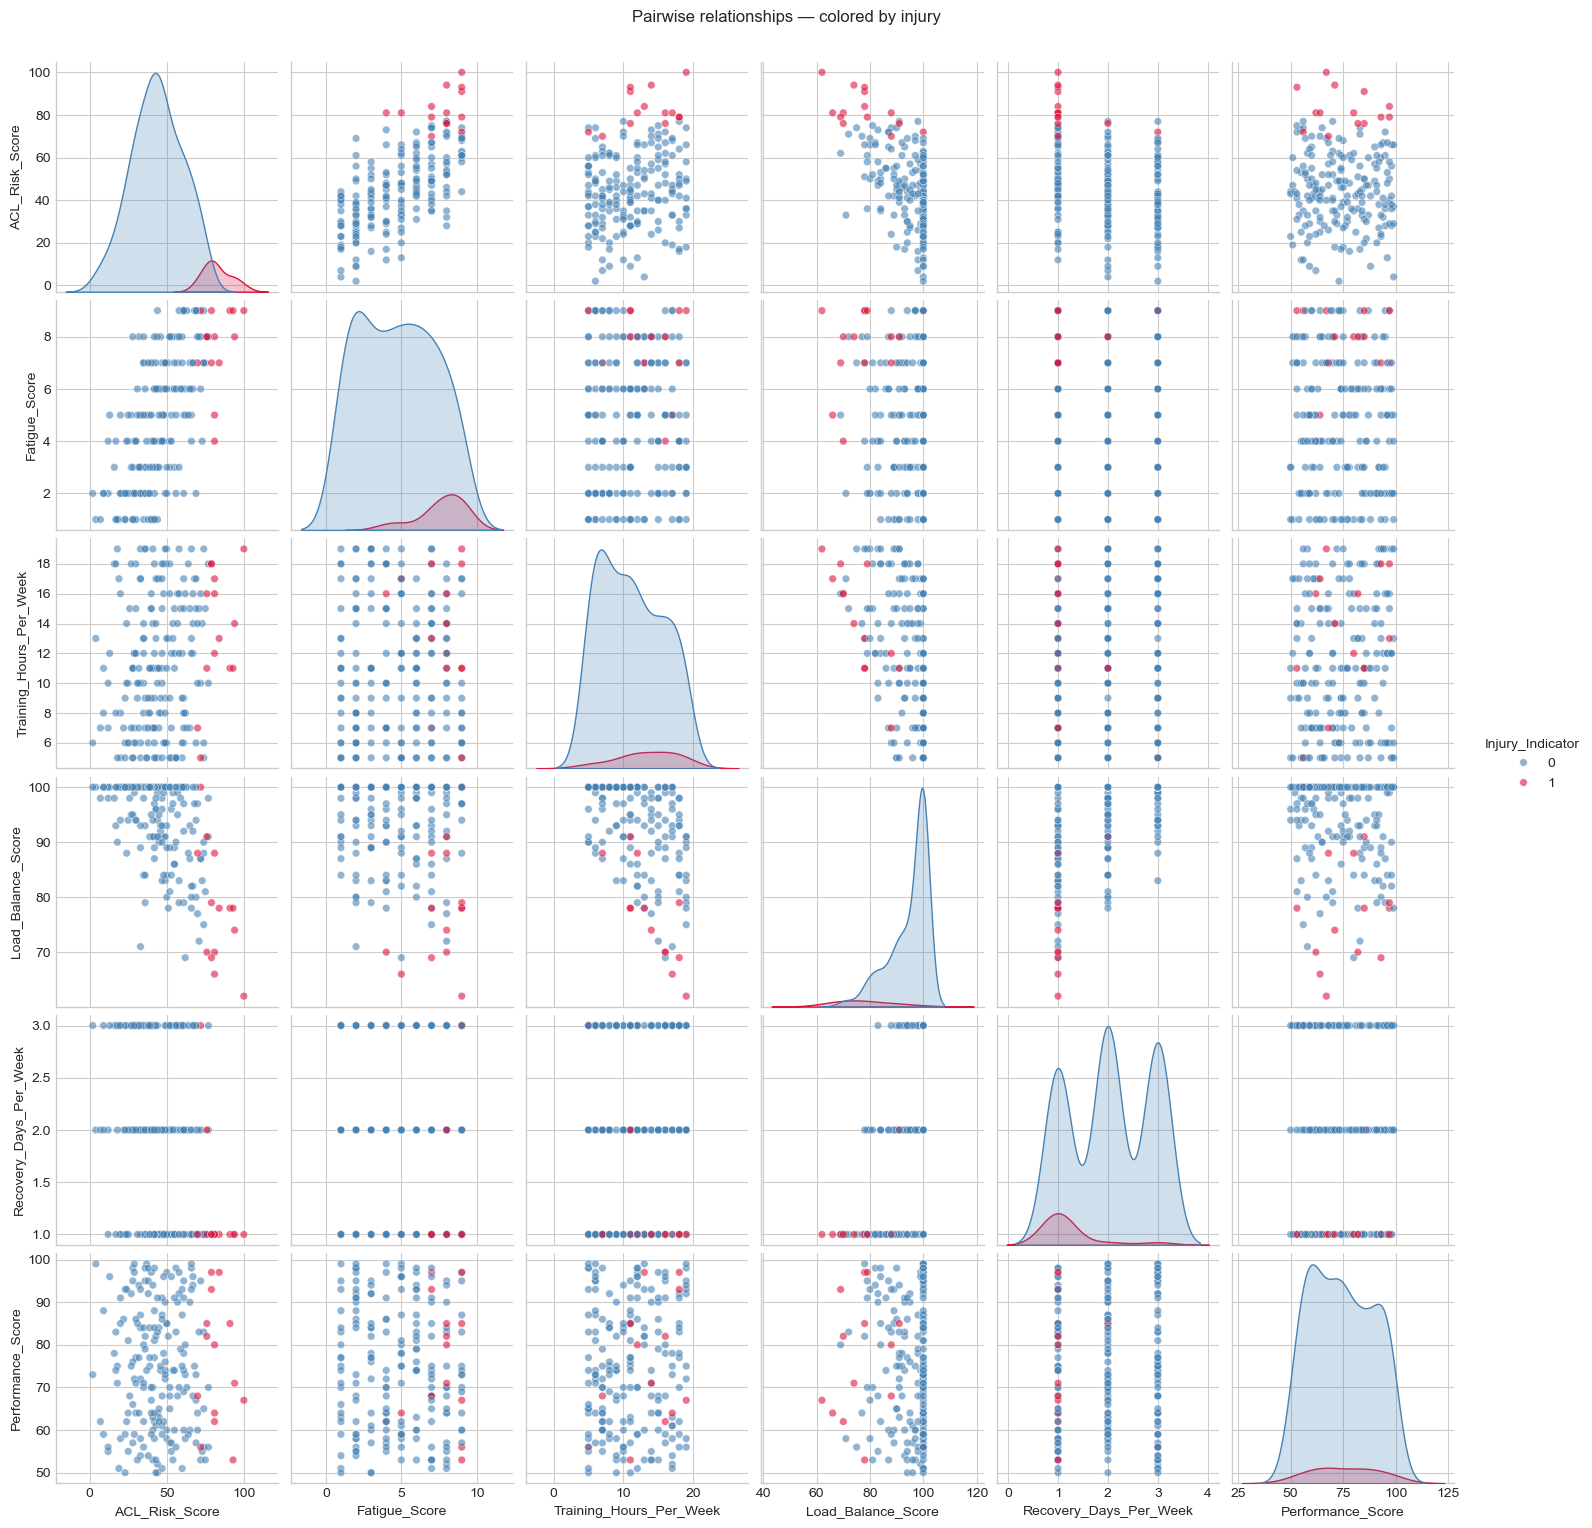

In [68]:
sns.pairplot(collegiate_df[top_feats + ['Injury_Indicator']], hue='Injury_Indicator',
             palette={0:'steelblue',1:'crimson'}, diag_kind='kde', plot_kws={'alpha':0.6, 's':30})
plt.suptitle('Pairwise relationships — colored by injury', y=1.02)
plt.show()

- ACL_Risk_Score: Shows the clearest separation between injured and non-injured athletes. Injured cases are concentrated at higher risk scores.
- Fatigue_Score: Injuries are more common at higher fatigue levels, supporting fatigue as an important risk factor.
- Training_Hours_Per_Week: Shows some positive association with injury but there is substantial overlap.
- Load_Balance_Score: Injured athletes tend to have lower scores while non-injured athletes are concentrated near higher scores.
- Recovery_Days_Per_Week: Injured athletes are more concentrated around fewer recovery days, while non-injured athletes are spread more across 2–3 days.
- Performance_Score: Considerable overlap between both groups, suggesting a weaker direct relationship with injury.

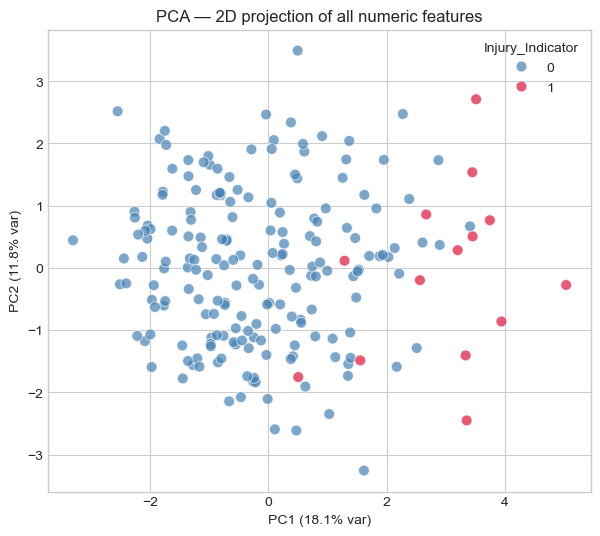

Top loadings on PC1:
 ACL_Risk_Score             0.579184
Load_Balance_Score        -0.533596
Fatigue_Score              0.345889
Recovery_Days_Per_Week    -0.333089
Training_Hours_Per_Week    0.283996
dtype: float64


In [73]:
X = StandardScaler().fit_transform(collegiate_df[num_cols])
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

plt.figure(figsize=(7,6))
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=collegiate_df['Injury_Indicator'],
                 palette={0:'steelblue',1:'crimson'}, alpha=0.7, s=60)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
plt.title('PCA — 2D projection of all numeric features')
plt.show()
print("Top loadings on PC1:\n", pd.Series(pca.components_[0], index=num_cols).sort_values(key=abs, ascending=False).head(5))

PC1 appears to represent an overall injury-risk/workload dimension. Higher ACL risk, higher fatigue and more training contribute positively while higher load balance and recovery contribute negatively.

The fact that injured athletes tend to appear on the positive PC1 side supports the earlier findings that injury is strongly associated with fatigue, ACL risk, workload and recovery-related factors. However, because the classes still overlap substantially, multiple features and non-linear relationships are needed for accurate injury prediction.

### Useful features and patterns

Strong features:

- ACL_Risk_Score
- Fatigue_Score
- Load_Balance_Score
- Training_Intensity
- Recovery_Days_Per_Week
- Training_Hours_Per_Week

Moderate/supporting features:

- Match_Count_Per_Week
- Rest_Between_Events_Days
- Performance_Score
- Team_Contribution_Score

Weak standalone features:

- Age
- Height_cm
- Weight_kg
- Gender
- Position

Higher ACL risk is strongly associated with injury.
Higher fatigue is associated with more injuries.
Higher training intensity and training volume show increased injury tendency.
Lower load balance appears associated with injuries.
Athletes with fewer recovery days appear more injury-prone.
Performance and demographic variables show considerable overlap between injured and non-injured groups.
PCA showed some separation of injured athletes mainly along PC1 but the classes still overlap considerably.

### SECTION 2 — University Football Injury Dataset

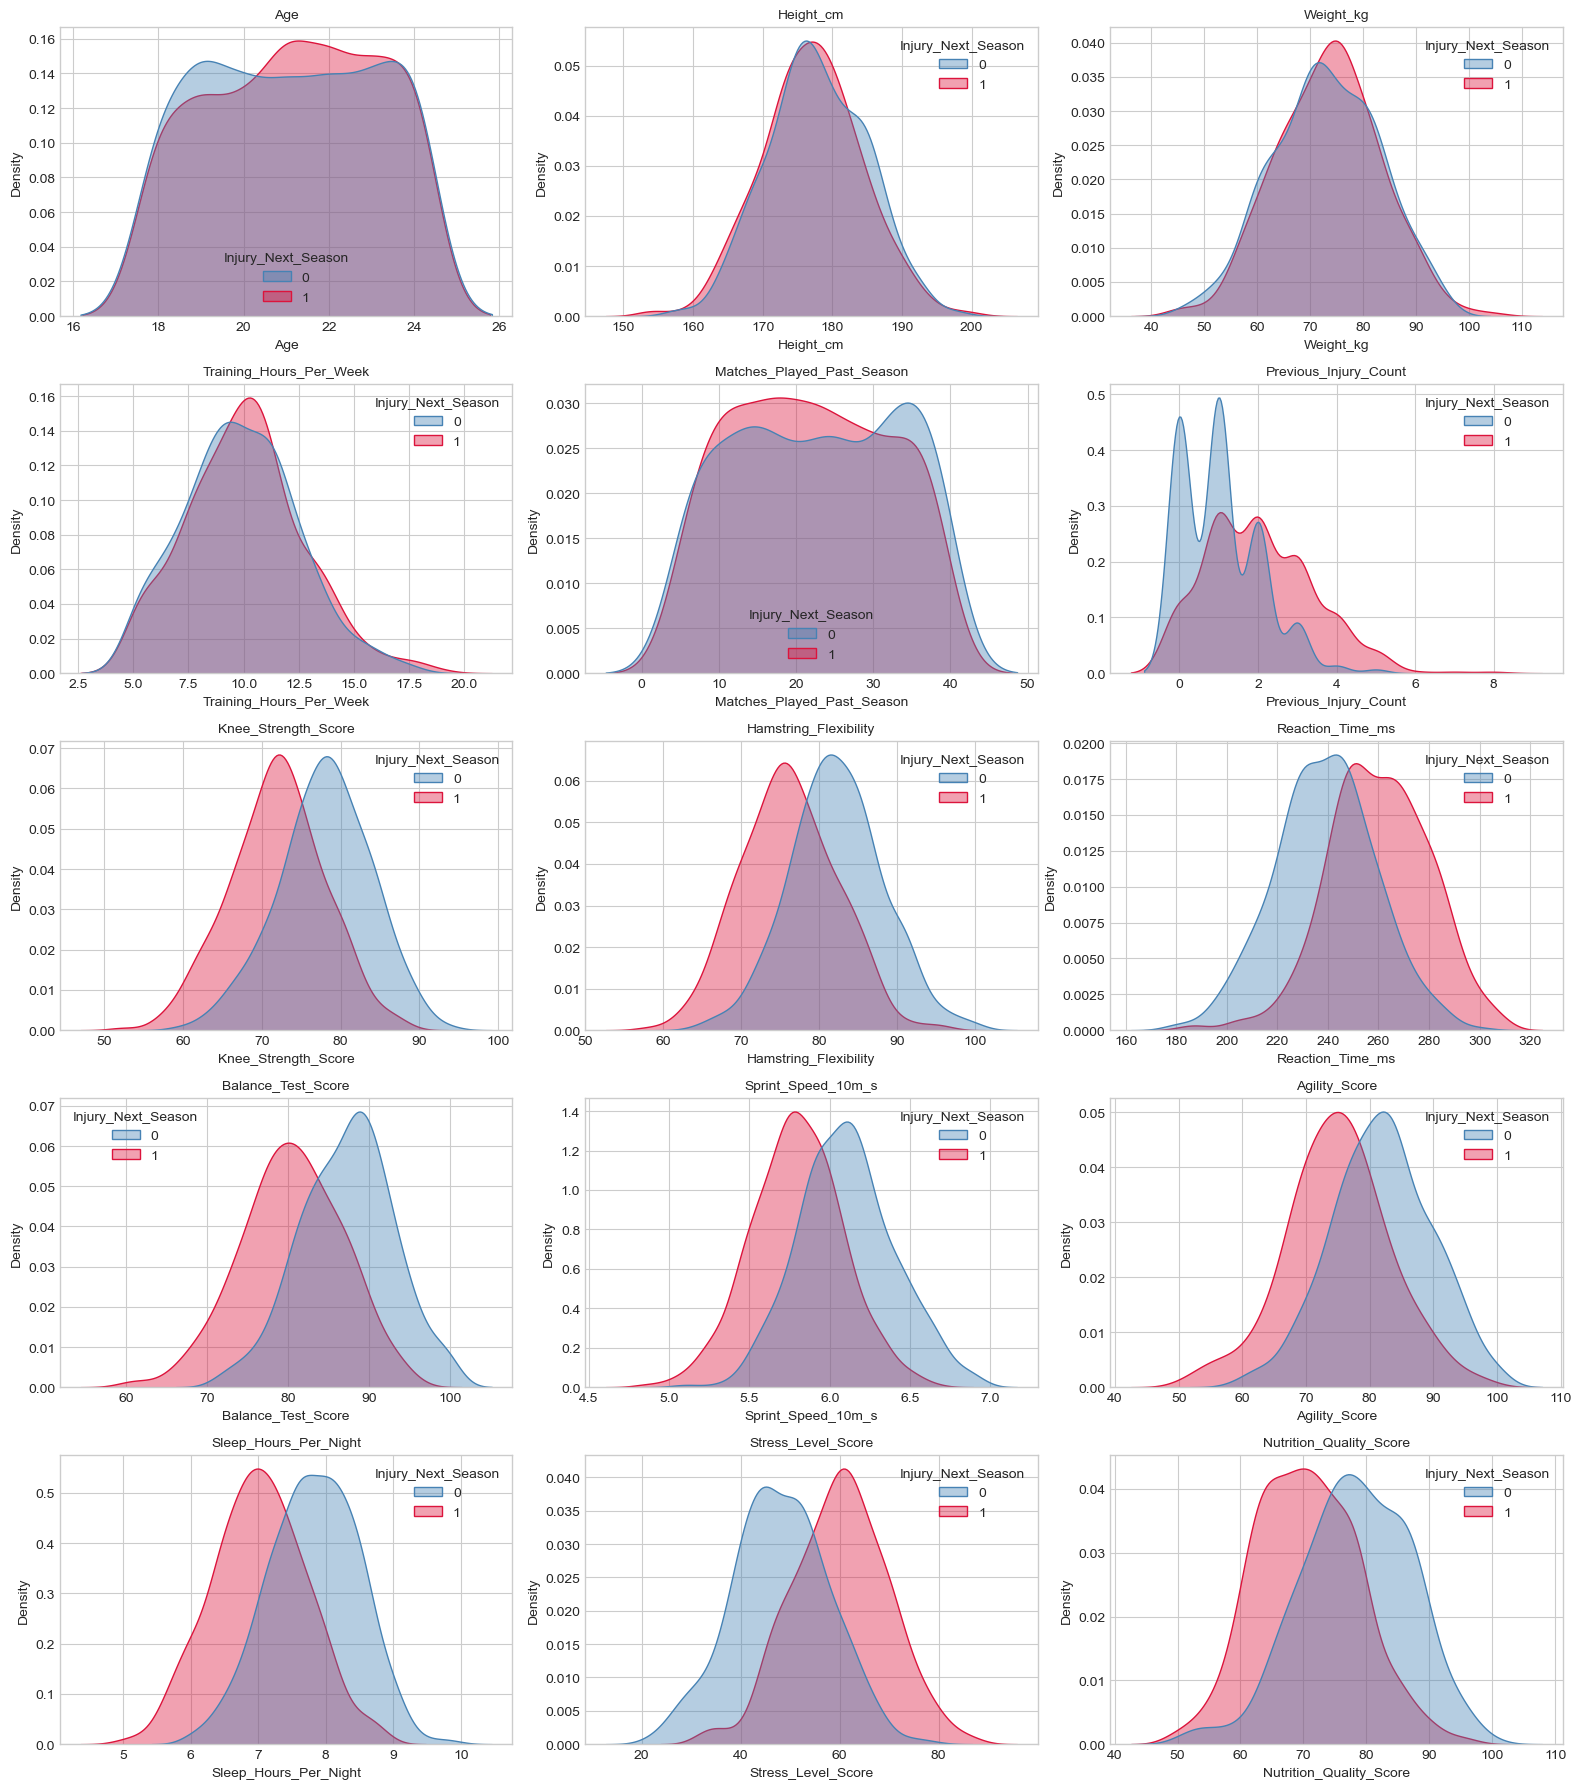

In [77]:
uni_num = ['Age','Height_cm','Weight_kg','Training_Hours_Per_Week','Matches_Played_Past_Season',
           'Previous_Injury_Count','Knee_Strength_Score','Hamstring_Flexibility','Reaction_Time_ms',
           'Balance_Test_Score','Sprint_Speed_10m_s','Agility_Score','Sleep_Hours_Per_Night',
           'Stress_Level_Score','Nutrition_Quality_Score']

fig, axes = plt.subplots(5, 3, figsize=(16, 18))
for ax, col in zip(axes.flatten(), uni_num):
    sns.kdeplot(data=university_df, x=col, hue='Injury_Next_Season', fill=True,
                palette={0:'steelblue',1:'crimson'}, alpha=0.4, ax=ax, common_norm=False)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

The strongest signals appear to be:

Previous injury history, knee strength, hamstring flexibility, balance, sleep, stress and nutrition.

So the injury prediction story for this dataset is less about pure training load and more about previous injury history, physical conditioning and recovery/readiness.

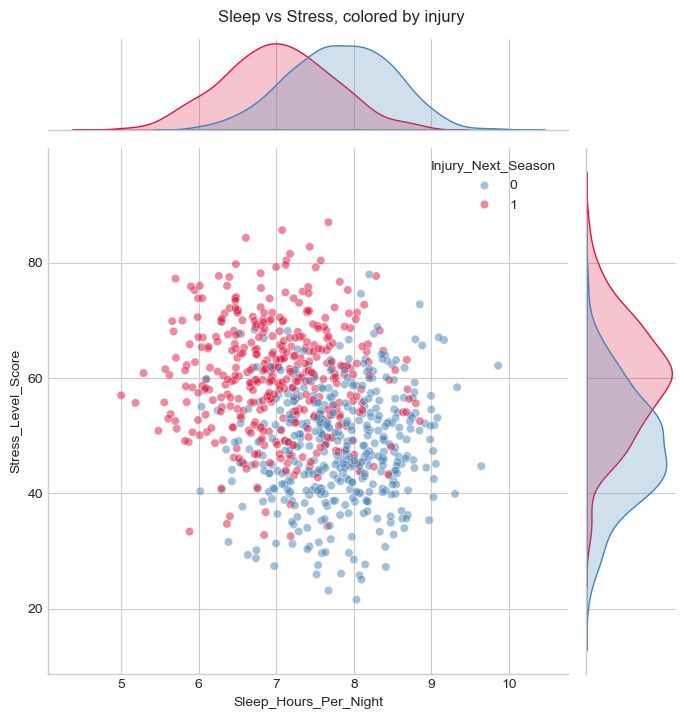

In [86]:
sns.jointplot(data=university_df, x='Sleep_Hours_Per_Night', y='Stress_Level_Score',
              hue='Injury_Next_Season', palette={0:'steelblue',1:'crimson'}, alpha=0.5, height=7)
plt.suptitle('Sleep vs Stress, colored by injury', y=1.02)
plt.show()

This joint plot shows a fairly clear relationship between sleep, stress and future injury.

Injured athletes (red) tend to have higher stress levels, mostly around 50–70+.
They also tend to have slightly lower sleep, generally around 6–8 hours.
Non-injured athletes (blue) are more concentrated around 7–9 hours of sleep and lower stress levels around 35–60.
There is still substantial overlap between the two groups, so sleep and stress are not sufficient alone to predict injury.
The plot suggests an important combined pattern: lower sleep + higher stress is associated with greater injury risk.

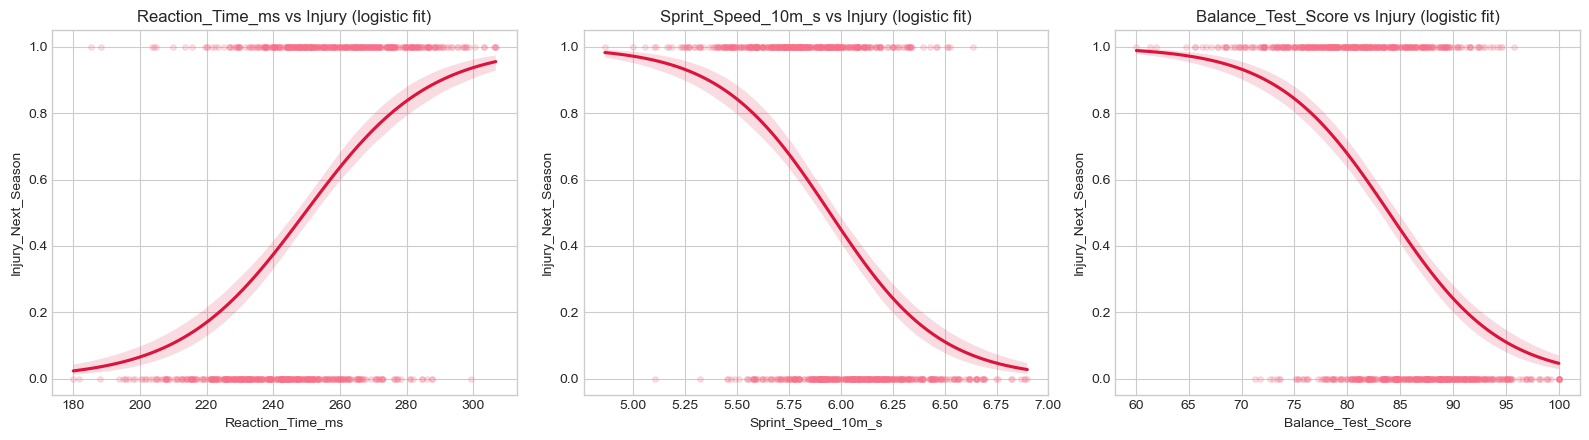

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['Reaction_Time_ms','Sprint_Speed_10m_s','Balance_Test_Score']):
    sns.regplot(x=col, y='Injury_Next_Season', data=university_df, ax=ax,
                logistic=True, scatter_kws={'alpha':0.2, 's':15}, line_kws={'color':'crimson'})
    ax.set_title(f'{col} vs Injury (logistic fit)')
plt.tight_layout()
plt.show()

These plots show how the probability of next-season injury changes with each feature.

- Reaction_Time_ms: Injury probability increases as reaction time increases. Athletes with slower reaction times, particularly above roughly 250 ms, show higher predicted injury probability.
- Sprint_Speed_10m_s: Injury probability decreases as sprint speed increases. Lower sprint speed is associated with greater injury risk.
- Balance_Test_Score: Injury probability decreases as balance score increases. Lower balance scores are associated with higher injury risk.

This suggests that neuromuscular performance and physical stability are meaningful predictors of next-season injury. The logistic curves also indicate that these relationships are not simply linear across the entire range.

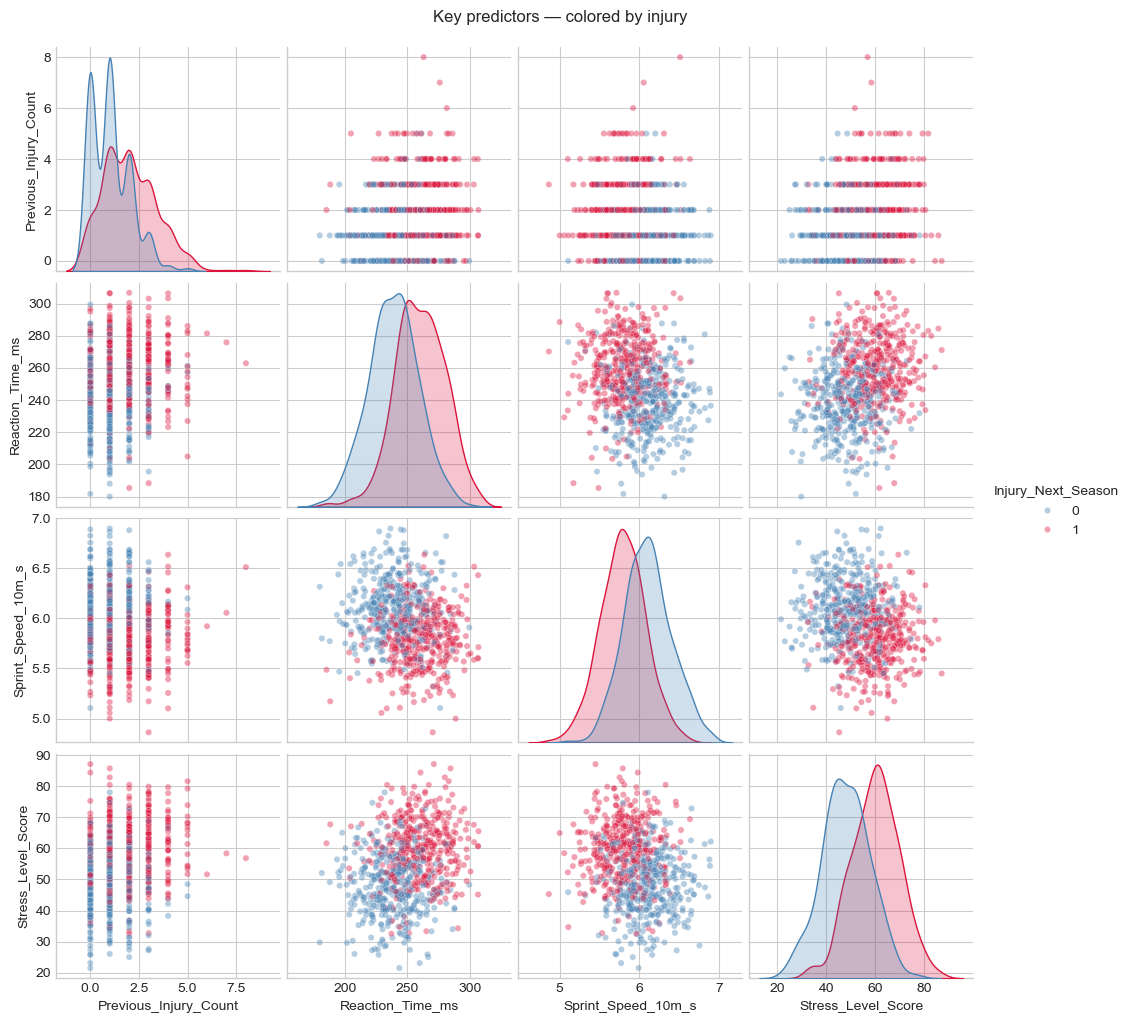

In [94]:
g = sns.pairplot(university_df, vars=['Previous_Injury_Count','Reaction_Time_ms','Sprint_Speed_10m_s','Stress_Level_Score'],
                  hue='Injury_Next_Season', palette={0:'steelblue',1:'crimson'}, diag_kind='kde', plot_kws={'alpha':0.4, 's':20})
g.fig.suptitle('Key predictors — colored by injury', y=1.02)
plt.show()

This pairplot focuses on four potentially important predictors of Injury_Next_Season.

- Previous_Injury_Count: One of the clearest signals. Injured athletes tend to have a higher number of previous injuries. The red distribution is shifted toward higher counts.
- Reaction_Time_ms: Injured athletes tend to have higher reaction times, indicating slower reactions. The red distribution is shifted to the right.
- Sprint_Speed_10m_s: Injured athletes tend to have slightly lower sprint speeds. There is considerable overlap, so the relationship is weaker than reaction time.
- Stress_Level_Score: Shows clear separation. Injured athletes generally have higher stress levels, while non-injured athletes are concentrated at lower levels.

The pairplot reinforces the idea that the strongest predictors are related to injury history, physical performance and psychological/recovery state.

The most promising features from this analysis are:

Previous_Injury_Count, Reaction_Time_ms and Stress_Level_Score, followed by Sprint_Speed_10m_s.

It also suggests that interactions between these variables could be useful, rather than relying only on their individual effects.


### Target Variables & Class Imbalance
Let's inspect the target columns for the injury classification datasets: `Injury_Indicator` in `collegiate_df` and `Injury_Next_Season` in `university_df`.


Collegiate Injury Rate: 7.000000000000001 %
University Injury Rate: 50.0 %


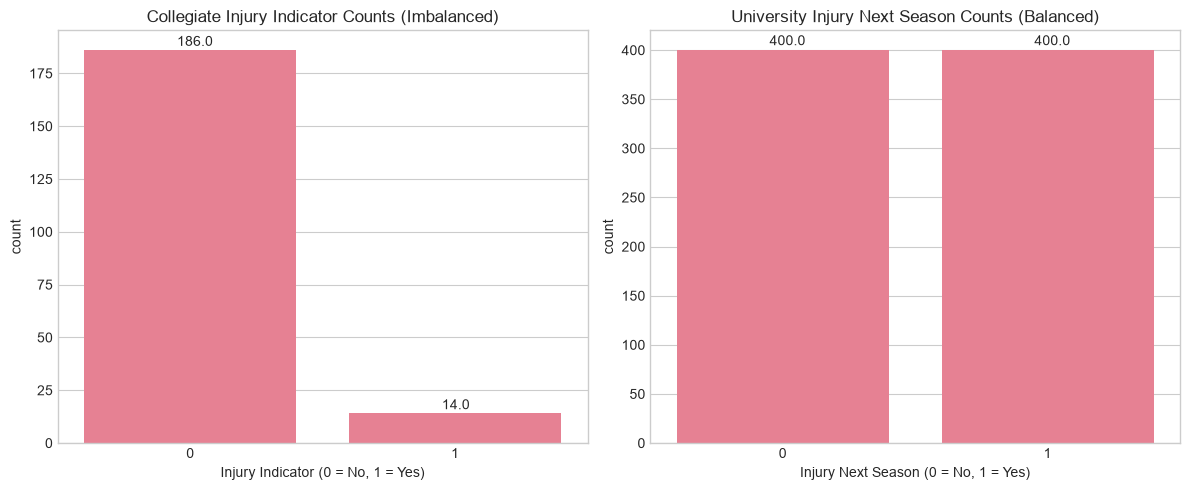

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x='Injury_Indicator', data=collegiate_df, ax=axes[0])
axes[0].set_title('Collegiate Injury Indicator Counts (Imbalanced)')
axes[0].set_xlabel('Injury Indicator (0 = No, 1 = Yes)')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()}', (p.get_x()+0.35, p.get_height()+2))

sns.countplot(x='Injury_Next_Season', data=university_df, ax=axes[1])
axes[1].set_title('University Injury Next Season Counts (Balanced)')
axes[1].set_xlabel('Injury Next Season (0 = No, 1 = Yes)')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height()}', (p.get_x()+0.35, p.get_height()+5))

plt.tight_layout()
plt.show()

print('Collegiate Injury Rate:', collegiate_df['Injury_Indicator'].mean() * 100, '%')
print('University Injury Rate:', university_df['Injury_Next_Season'].mean() * 100, '%')


### Useful features and patterns

The strongest features for predicting Injury_Next_Season are:

- Very strong: Previous_Injury_Count
- Strong: Knee_Strength_Score, Hamstring_Flexibility, Balance_Test_Score, Reaction_Time_ms, Stress_Level_Score and Sleep_Hours_Per_Night
- Moderate: Nutrition_Quality_Score, Agility_Score, Sprint_Speed_10m_s, Training_Hours_Per_Week and Matches_Played_Past_Season
- Weak: Age, Height_cm and Weight_kg

Useful derived features
- Injury_History_Binary
- Sleep_Stress_Risk
- Neuromuscular_Risk
- Seasonal_Load
- Match_Training_Ratio
- Physical_Readiness_Score
- Recovery_Risk

Overall takeaway: The EDA suggests that future injury is mainly influenced by previous injury history, physical readiness, recovery and workload. The next step should be to compare a baseline model using original features with a feature-engineered model and evaluate whether the derived features actually improve prediction.

### SECTION 3 — Football Dataset

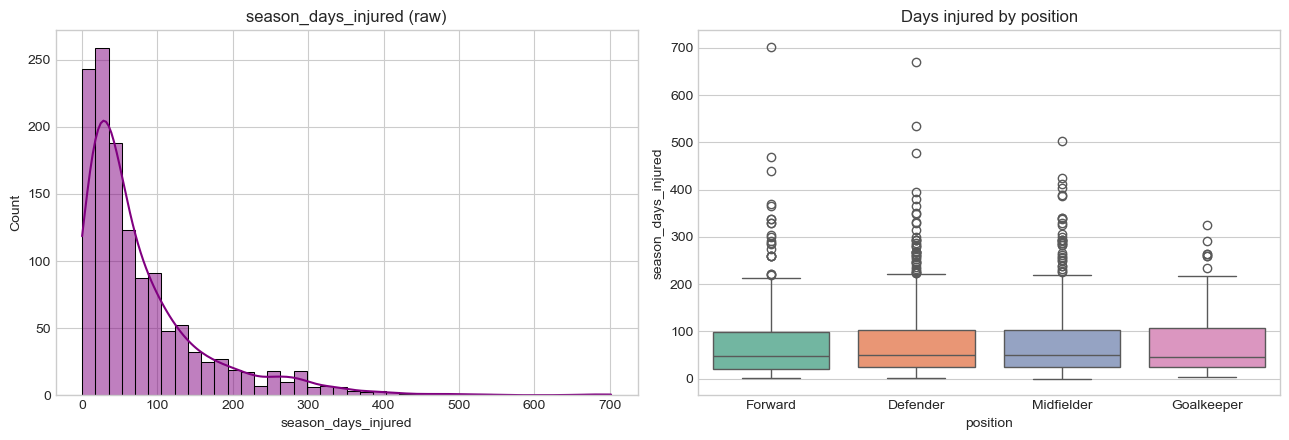

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.histplot(football_df['season_days_injured'], bins=40, kde=True, ax=axes[0], color='purple')
axes[0].set_title('season_days_injured (raw)')
sns.boxplot(x='position', y='season_days_injured', data=football_df, ax=axes[1], palette='Set2')
axes[1].set_title('Days injured by position')
plt.tight_layout()
plt.show()

season_days_injured is strongly right-skewed.
Most players have fewer than 100 injury days while a small number have very long injury periods.
There are several extreme outliers, reaching around 300–700 days.
Injury duration is fairly similar across positions overall.
Defenders and midfielders show several high-duration outliers while forwards also have some extreme cases.
For modelling, outlier handling or a transformation may be useful because of the skewed distribution.

Overall: Injury duration varies greatly between players, but position does not show a strong difference in typical injury duration.

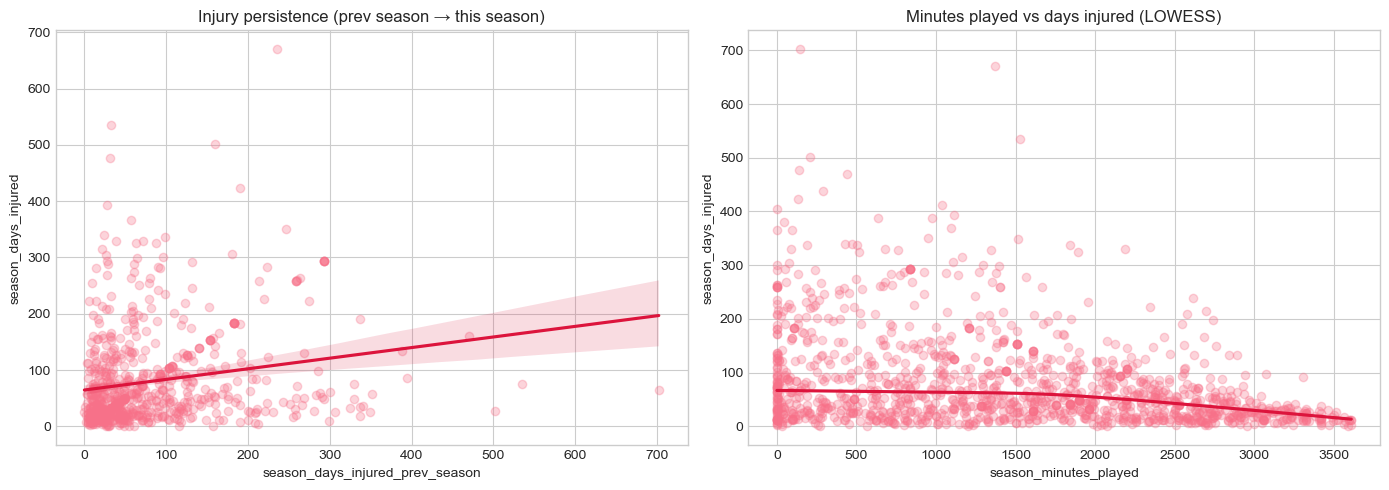

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.regplot(x='season_days_injured_prev_season', y='season_days_injured', data=football_df,
            ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'crimson'})
axes[0].set_title('Injury persistence (prev season → this season)')

sns.regplot(x='season_minutes_played', y='season_days_injured', data=football_df,
            ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'crimson'}, lowess=True)
axes[1].set_title('Minutes played vs days injured (LOWESS)')
plt.tight_layout()
plt.show()

- Previous-season injury days vs current injury days: Shows a positive relationship. Players who had more injury days in the previous season tend to have more injury days this season.
- The relationship is not very strong because there is large variation and many outliers, but previous injury duration is still an important signal.
- Minutes played vs injury days: Shows a weak negative relationship. Players with more minutes tend to have slightly fewer injury days.
- The relationship is highly scattered, so minutes played alone is not a strong predictor of injury duration.
- The LOWESS curve suggests the negative relationship becomes more noticeable at higher playing minutes.

Overall: Previous injury history appears to be more informative than playing minutes. This supports using previous injury duration as a key predictive feature, while treating minutes played as a supporting variable.

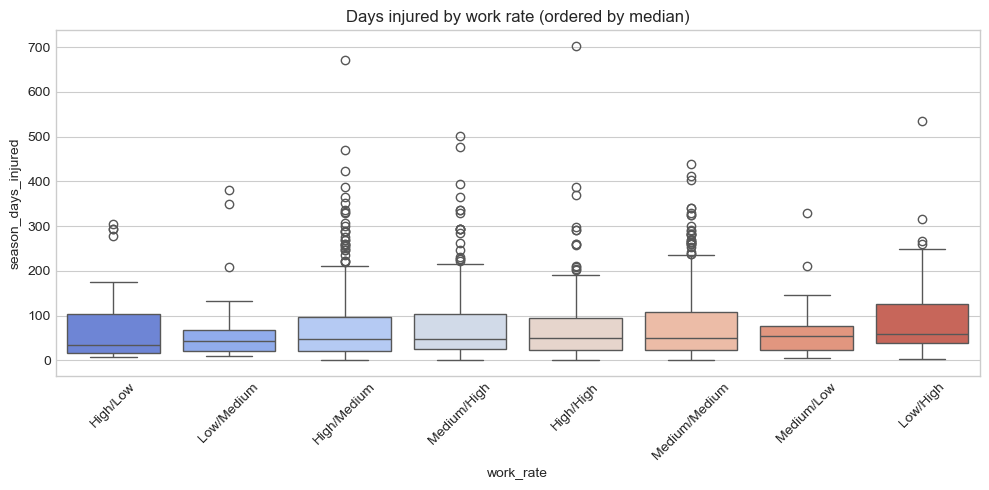

In [111]:
plt.figure(figsize=(10,5))
order = football_df.groupby('work_rate')['season_days_injured'].median().sort_values().index
sns.boxplot(x='work_rate', y='season_days_injured', data=football_df, order=order, palette='coolwarm')
plt.xticks(rotation=45)
plt.title('Days injured by work rate (ordered by median)')
plt.tight_layout()
plt.show()

Players with higher work rates generally show slightly higher median injury days.
Low/Low has one of the lowest typical injury durations.
Low/High shows the highest median injury duration among the groups.
High/Low also shows relatively high injury days.
The differences between work-rate groups are not very large compared with the overall variation.
Almost every group contains many high-duration outliers, with some players reaching 300–700 injury days.

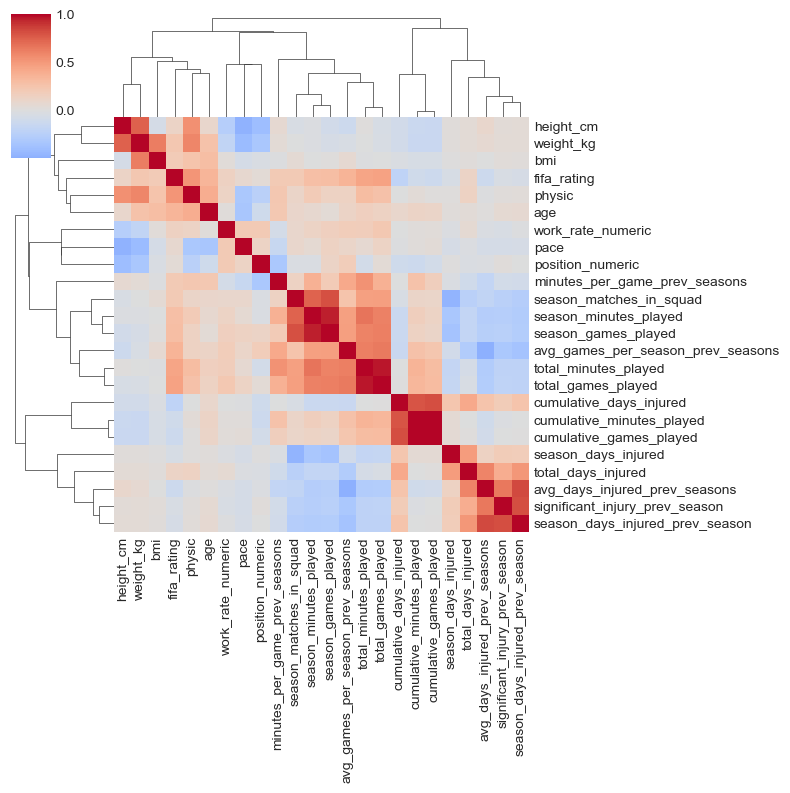

In [118]:
football_num = football_df.select_dtypes(include=np.number).drop(columns=['start_year'], errors='ignore')
sns.clustermap(football_num.corr(), cmap='coolwarm', center=0, figsize=(8,8))
plt.show()

Height, weight, BMI and physical attributes show strong correlations with each other, which is expected.
Season minutes, games played and total minutes/games are strongly correlated, indicating redundant workload features.
Cumulative minutes and cumulative games are also strongly related to each other and to other playing-time variables.
season_days_injured shows a positive relationship with previous injury-related variables, supporting the earlier finding that injury history is important.
significant_injury_prev_season and previous injury-duration features appear closely related and may provide useful historical injury information.
Some features such as pace, work_rate_numeric and position_numeric show weaker correlations with injury duration.

### Lifestyle and Physical Screening Correlation Analysis
We investigate how physical screening parameters (knee strength, flexibility, reaction time, balance) and lifestyle scores (sleep, stress, nutrition) correlate with next-season injury.


Top Correlated Variables with Injury_Next_Season:
Injury_Next_Season            1.000000
Stress_Level_Score            0.529961
Reaction_Time_ms              0.470878
Previous_Injury_Count         0.382226
BMI                           0.047380
Training_Hours_Per_Week       0.033793
Age                           0.021359
Weight_kg                     0.021163
Matches_Played_Past_Season   -0.043910
Height_cm                    -0.054937
Warmup_Routine_Adherence     -0.265089
Agility_Score                -0.393681
Nutrition_Quality_Score      -0.412496
Hamstring_Flexibility        -0.450317
Knee_Strength_Score          -0.454551
Sprint_Speed_10m_s           -0.471499
Balance_Test_Score           -0.494814
Sleep_Hours_Per_Night        -0.510869
Name: Injury_Next_Season, dtype: float64


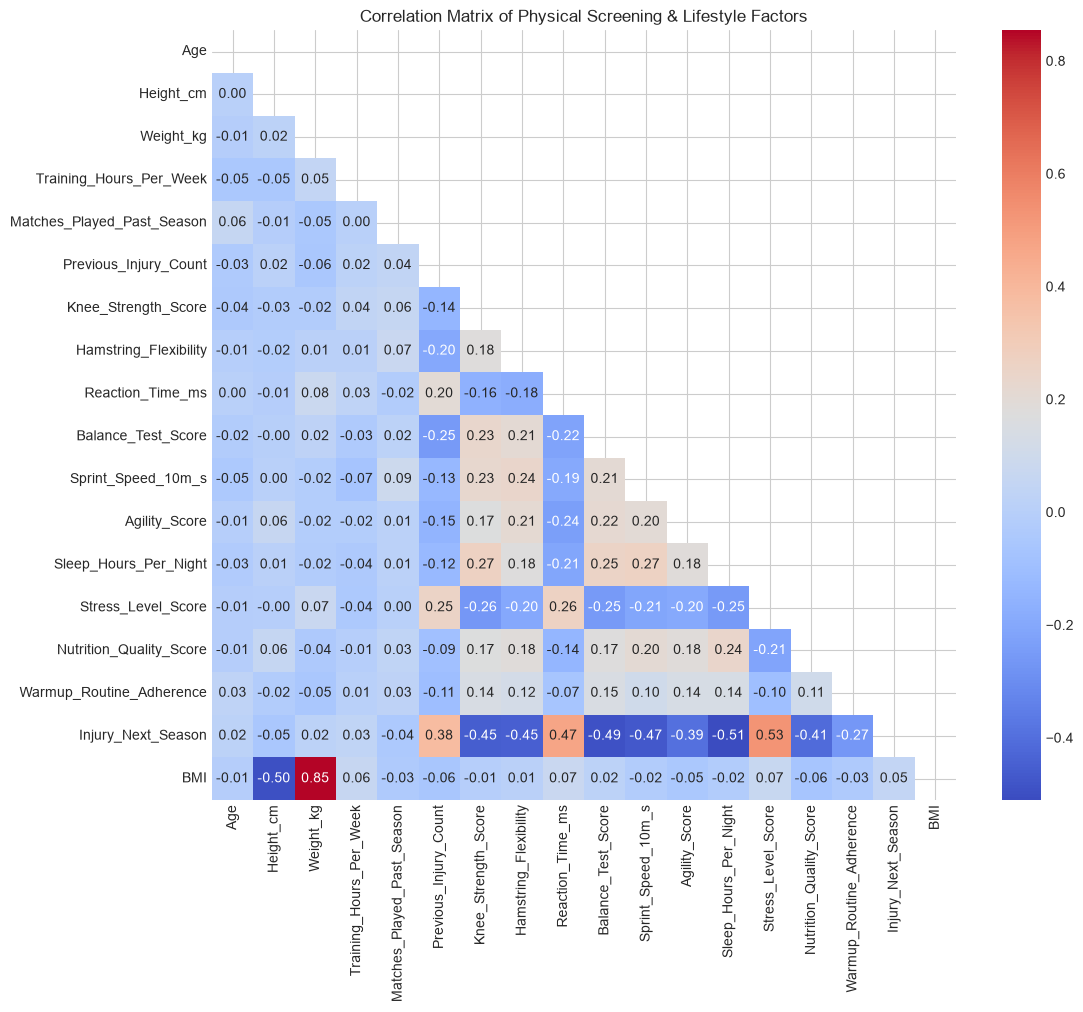

In [7]:
plt.figure(figsize=(12, 10))
uni_numeric = university_df.select_dtypes(include=[np.number])
corr_matrix = uni_numeric.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=np.triu(np.ones_like(corr_matrix, dtype=bool)))
plt.title('Correlation Matrix of Physical Screening & Lifestyle Factors')
plt.show()

print('Top Correlated Variables with Injury_Next_Season:')
print(corr_matrix['Injury_Next_Season'].sort_values(ascending=False))


### Useful features and patterns

Strong features:

- season_days_injured_prev_season
- significant_injury_prev_season
- cumulative_days_injured
- avg_days_injured_prev_seasons
- cumulative_minutes_played
- total_minutes_played
- total_games_played
- minutes_per_game_prev_seasons

Useful supporting features:

- work_rate
- season_minutes_played
- season_games_played
- avg_games_played_prev_seasons
- age
- physic
- pace
- position

Useful derived features:

- Previous_Injury_Burden
- Injury_Frequency
- Minutes_Per_Game
- Season_Workload
- Previous_Workload
- Injury_Exposure_Ratio
- Injury_Severity_Index
- Key takeaway

The main predictive signal comes from how much and how recently a player has been injured, followed by playing exposure and workload.

There is also strong correlation among several minutes and games variables, so rather than keeping every redundant feature, create meaningful features that capture injury burden relative to playing exposure.

### SECTION 4 — Wearable Telemetry

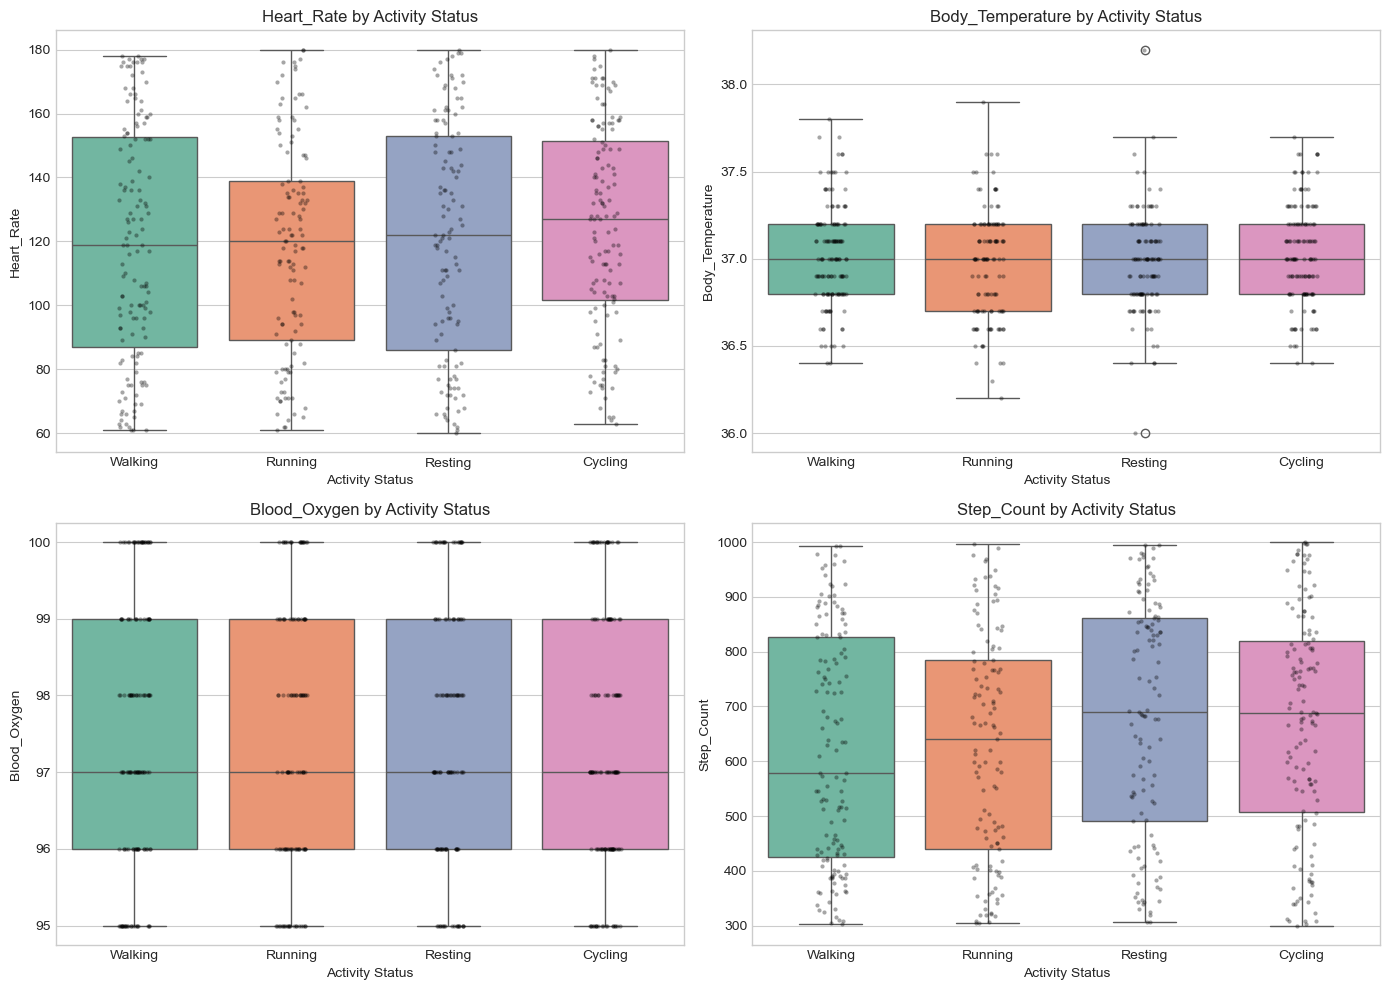

In [138]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = ['Heart_Rate', 'Body_Temperature', 'Blood_Oxygen', 'Step_Count']

for ax, col in zip(axes.flatten(), features):
    sns.boxplot(x='Activity_Status',y=col,data=wearable_df,ax=ax,palette='Set2')   
    sns.stripplot(x='Activity_Status',y=col,data=wearable_df,ax=ax,color='black',alpha=0.35,size=3)   
    ax.set_title(f'{col} by Activity Status')
    ax.set_xlabel('Activity Status')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

- Heart Rate: Shows noticeable variation across activity types. Running has a slightly lower median than cycling and resting while walking has a wide spread.
- Body Temperature: Very similar across all activities with medians around 37°C. It appears to be a weak differentiating feature.
- Blood Oxygen: Almost identical across all activity groups with values concentrated around 96–99%. This provides little separation.
- Step Count: Shows more variation. Resting and cycling have higher median step counts while walking has a wider spread and running has a slightly lower median.
- Overall intuition

Among these wearable features, Heart Rate and Step Count show the most variation across activity status and are likely more useful for modelling.

Body Temperature and Blood Oxygen appear relatively stable across activities and are likely weaker standalone predictors.

The individual observations also show substantial overlap between groups, suggesting that combinations of wearable signals may be more informative than any single measurement.

<Figure size 900x600 with 0 Axes>

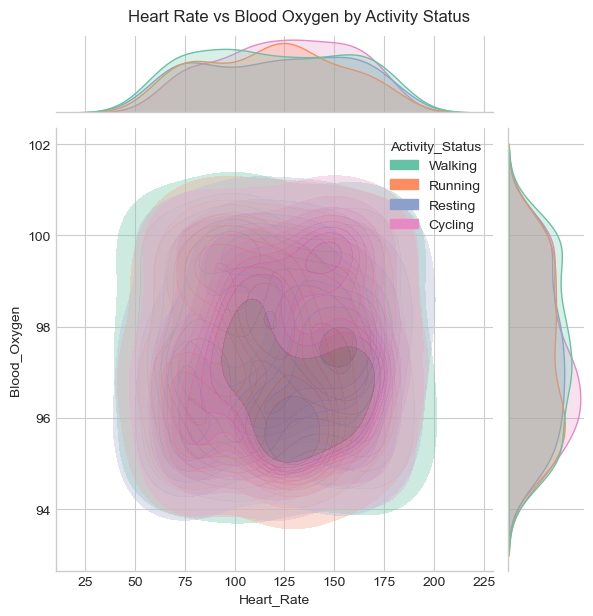

In [145]:
plt.figure(figsize=(9, 6))

sns.jointplot(data=wearable_df,x='Heart_Rate',y='Blood_Oxygen',hue='Activity_Status',kind='kde',palette='Set2',fill=True,alpha=0.4)

plt.suptitle('Heart Rate vs Blood Oxygen by Activity Status',y=1.02)

plt.show()

The distributions for all four activities overlap heavily, meaning there is no strong separation between activity types based on these two features.
Heart rate varies widely across activities, roughly from 50 to 180+, but the density regions are quite similar.
Blood oxygen is tightly concentrated around 95–100% for all activities.
There is no obvious strong relationship between heart rate and blood oxygen in this dataset.
The marginal KDE plots also show very similar distributions across activity groups.

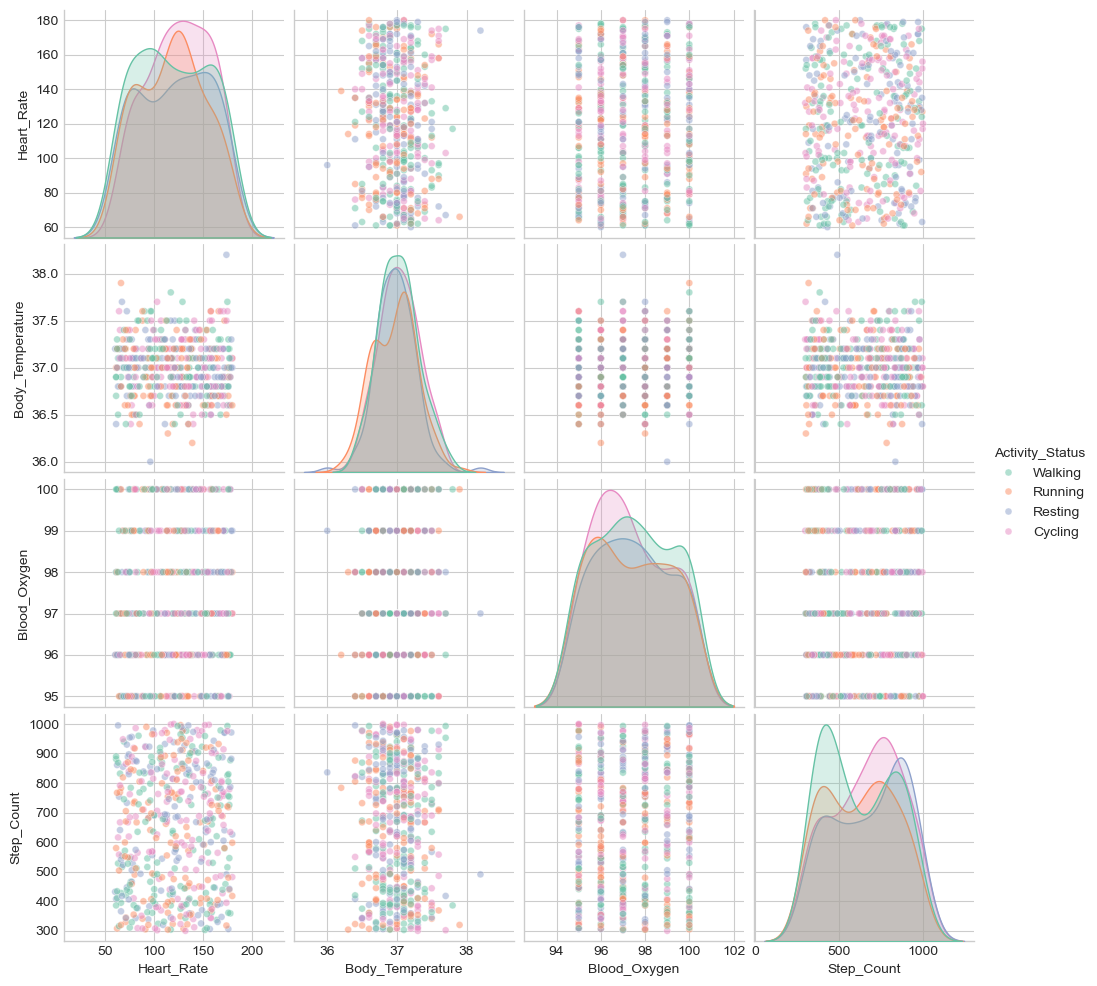

In [153]:
sns.pairplot(wearable_df[['Heart_Rate','Body_Temperature','Blood_Oxygen','Step_Count','Activity_Status']],
             hue='Activity_Status', palette='Set2', diag_kind='kde', plot_kws={'alpha':0.5, 's':25})
plt.show()

There is no strong visible correlation between Heart Rate and Blood Oxygen.
Body Temperature also appears largely independent of the other measurements.
Step Count has substantial variation but does not show a clear linear relationship with Heart Rate.
The large overlap between activity groups means that no single wearable feature clearly separates the activity categories.

### Useful features and patterns

Strong features:

- Heart_Rate
- Step_Count

- Moderate: Body_Temperature
- Weak: Blood_Oxygen

Useful derived features:

- Heart Rate Intensity
- Steps-to-Heart-Rate Ratio
- Heart Rate × Step Count
- Body Temperature Deviation
- Combined Activity Intensity Score

Overall: Heart rate and step count show the most variation across activities while blood oxygen and body temperature remain relatively stable. Combining wearable signals and deriving activity-intensity features could provide more useful information than the raw measurements alone.

### 2.3 Raw Biomechanical Sensor Signal Processing
We process raw accelerometer and gyroscope signals from `A_DeviceMotion_data` to simulate a sports-science IMU module. A 4th-order low-pass Butterworth filter is applied to separate high-frequency movement signals from gravitational noise, followed by peak finding to count steps and cadence.


Signal Duration: 35.02 seconds
Steps Counted  : 45
Calculated Cadence: 77.10 steps/minute


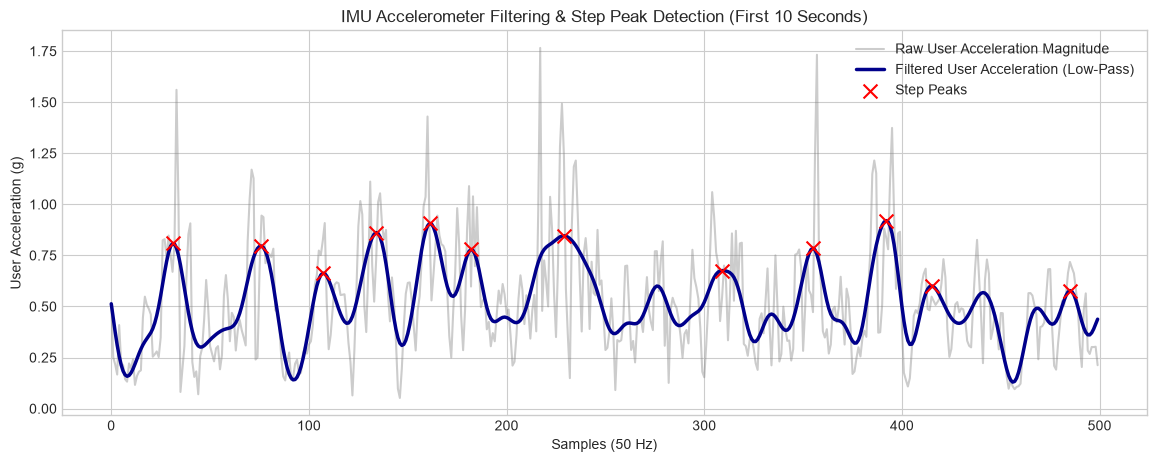

In [5]:
# Load a sample IMU file
imu_sample_path = 'data/A_DeviceMotion_data/dws_1/sub_1.csv'
if os.path.exists(imu_sample_path):
    imu_df = pd.read_csv(imu_sample_path)
    
    # Calculate Acceleration Magnitude
    acc_mag = np.sqrt(imu_df['userAcceleration.x']**2 + imu_df['userAcceleration.y']**2 + imu_df['userAcceleration.z']**2)
    
    # Low-pass filter (Butterworth, 3 Hz cutoff at 50 Hz sampling rate)
    fs = 50.0
    nyq = 0.5 * fs
    cutoff = 3.0
    b, a = butter(4, cutoff / nyq, btype='low')
    filtered_acc = filtfilt(b, a, acc_mag)
    
    # Peak detection (step counting)
    peaks, _ = find_peaks(filtered_acc, distance=15, prominence=0.2)
    
    # Plot Raw vs Filtered Acceleration & Detected Steps
    plt.figure(figsize=(14, 5))
    plt.plot(acc_mag.values[:500], alpha=0.4, label='Raw User Acceleration Magnitude', color='gray')
    plt.plot(filtered_acc[:500], label='Filtered User Acceleration (Low-Pass)', linewidth=2.5, color='darkblue')
    
    # Draw peaks within first 500 samples
    visible_peaks = [p for p in peaks if p < 500]
    plt.scatter(visible_peaks, filtered_acc[visible_peaks], color='red', marker='x', s=100, zorder=5, label='Step Peaks')
    
    plt.title('IMU Accelerometer Filtering & Step Peak Detection (First 10 Seconds)')
    plt.xlabel('Samples (50 Hz)')
    plt.ylabel('User Acceleration (g)')
    plt.legend()
    plt.show()
    
    # Calculate cadence
    total_time = len(imu_df) / fs
    cadence = (len(peaks) / total_time) * 60
    print(f'Signal Duration: {total_time:.2f} seconds')
    print(f'Steps Counted  : {len(peaks)}')
    print(f'Calculated Cadence: {cadence:.2f} steps/minute')
else:
    print('Sample IMU file not found.')


Output interpretation:

- Signal duration: 35.02 seconds
- Detected steps: 45
- Estimated cadence: 77.10 steps/minute
- The grey signal is the noisy raw acceleration.
- The blue signal is the smoothed filtered acceleration.
- The red X marks represent detected step peaks.

In [165]:
import glob

def imu_dataset_scan(base_path='data/A_DeviceMotion_data'):
    folders = sorted(os.listdir(base_path)) if os.path.exists(base_path) else []
    print(f"Found {len(folders)} trial folders: {folders}")
    records = []
    for folder in folders:
        activity = folder.split('_')[0]
        for f in glob.glob(os.path.join(base_path, folder, 'sub_*.csv')):
            try:
                d = pd.read_csv(f)
                acc = np.sqrt(d['userAcceleration.x']**2 + d['userAcceleration.y']**2 + d['userAcceleration.z']**2)
                rot = np.sqrt(d['rotationRate.x']**2 + d['rotationRate.y']**2 + d['rotationRate.z']**2)
                records.append({
                    'activity': activity,
                    'subject': os.path.basename(f).replace('.csv',''),
                    'trial': folder,
                    'n_samples': len(d),
                    'acc_mean': acc.mean(), 'acc_std': acc.std(), 'acc_max': acc.max(),
                    'rot_mean': rot.mean(), 'rot_std': rot.std()
                })
            except Exception as e:
                print(f"Skipped {f}: {e}")
    summary = pd.DataFrame(records)
    print(f"Parsed {len(summary)} files across {summary['activity'].nunique() if len(summary) else 0} activities")
    return summary

imu_summary = imu_dataset_scan()
imu_summary.head()

Found 15 trial folders: ['dws_1', 'dws_11', 'dws_2', 'jog_16', 'jog_9', 'sit_13', 'sit_5', 'std_14', 'std_6', 'ups_12', 'ups_3', 'ups_4', 'wlk_15', 'wlk_7', 'wlk_8']
Parsed 360 files across 6 activities


,activity,subject,trial,n_samples,acc_mean,acc_std,acc_max,rot_mean,rot_std
0,dws,sub_1,dws_1,1751,0.501065,0.262767,1.955246,2.050740,1.219460
1,dws,sub_10,dws_1,2678,0.412475,0.260906,1.713050,1.356675,0.727939
2,dws,sub_11,dws_1,2025,0.496910,0.295165,2.400431,1.804294,0.926519
3,dws,sub_12,dws_1,1522,0.920886,0.597889,5.838394,2.542101,1.266006
4,dws,sub_13,dws_1,1583,0.706560,0.432400,3.258996,2.101499,1.039398


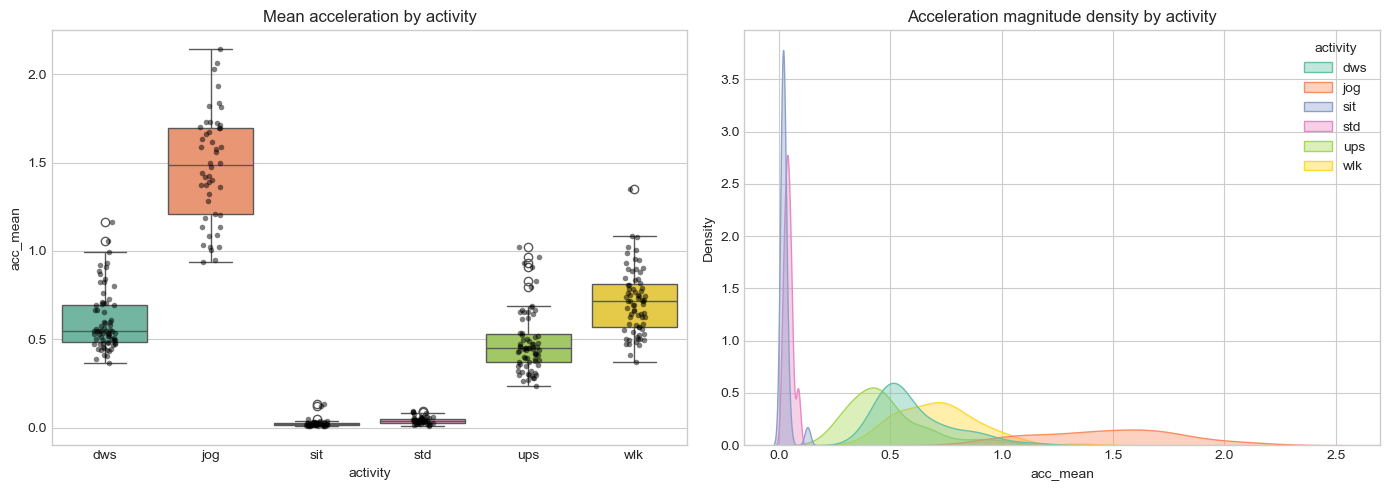

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(x='activity', y='acc_mean', data=imu_summary, ax=axes[0], palette='Set2')
axes[0].set_title('Mean acceleration by activity')
sns.stripplot(x='activity', y='acc_mean', data=imu_summary, ax=axes[0], color='black', size=4, alpha=0.5)

sns.kdeplot(data=imu_summary, x='acc_mean', hue='activity', fill=True, alpha=0.4, ax=axes[1], palette='Set2')
axes[1].set_title('Acceleration magnitude density by activity')
plt.tight_layout()
plt.show()

- Jogging (jog) has the highest mean acceleration by a large margin, indicating greater movement intensity.
- Wa lking (wlk) and downstairs (dws) show moderate acceleration.
- Upstairs (ups) also has moderate acceleration but with noticeable variation.
- Sitting (sit) and standing (std) have acceleration values close to zero, as expected.

The KDE plot confirms that different activities have distinct acceleration distributions, especially jogging versus stationary activities.

acc_mean is a useful feature for distinguishing activity intensity. Rather than using only raw acceleration, derived features such as mean acceleration, acceleration variance, peak acceleration and cadence could capture meaningful differences in movement and physical workload.


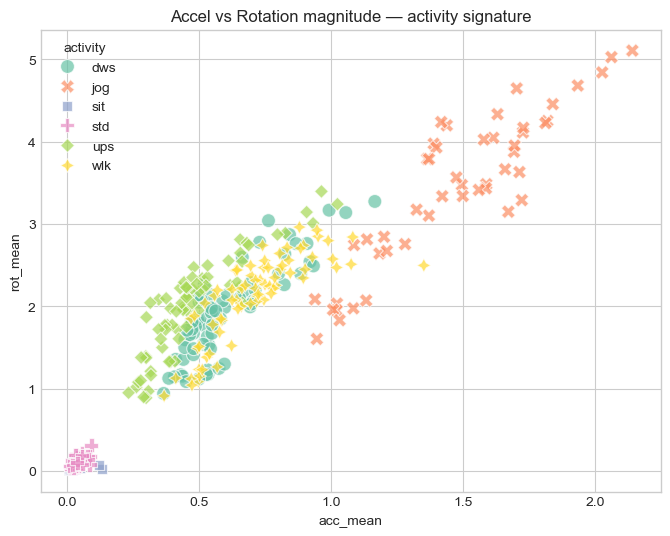

In [171]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='acc_mean', y='rot_mean', hue='activity', style='activity', data=imu_summary, s=100, alpha=0.7, palette='Set2')
plt.title('Accel vs Rotation magnitude — activity signature')
plt.show()

There is a clear positive relationship between acceleration magnitude (acc_mean) and rotation magnitude (rot_mean).
Jogging is clearly separated from the other activities with much higher acceleration and rotation values.
Sitting and standing form a tight cluster near zero, indicating very little movement.
Walking, upstairs and downstairs occupy the middle region and show considerable overlap.
The combination of acceleration and rotation provides a better activity signature than either feature alone.

acc_mean + rot_mean are strong features for identifying movement intensity and activity type. For the injury/wearable analysis, useful derived features could include combined motion intensity, acceleration-to-rotation ratio and overall movement variability.

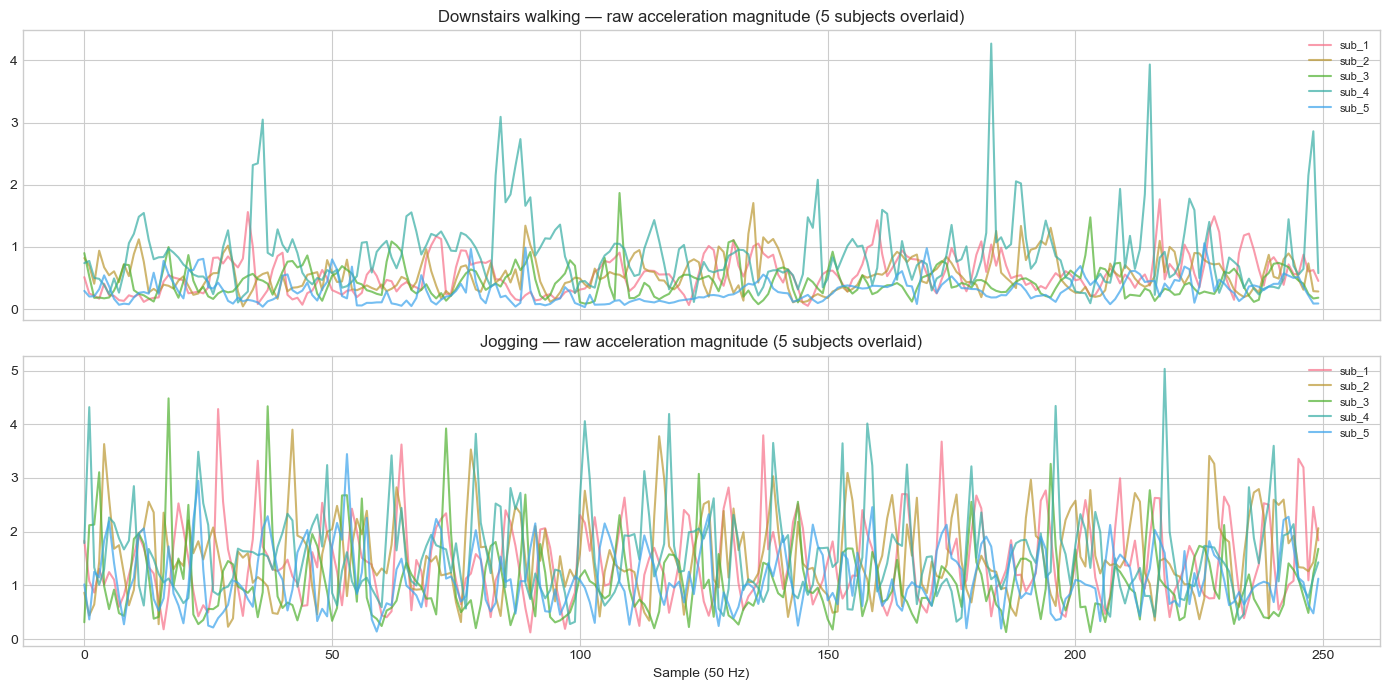

In [178]:
def load_raw_signal(activity_prefix, subject_num, base_path='data/A_DeviceMotion_data'):
    folder = next((f for f in os.listdir(base_path) if f.startswith(activity_prefix)), None)
    if folder is None:
        return None
    path = os.path.join(base_path, folder, f'sub_{subject_num}.csv')
    if not os.path.exists(path):
        return None
    d = pd.read_csv(path)
    acc = np.sqrt(d['userAcceleration.x']**2 + d['userAcceleration.y']**2 + d['userAcceleration.z']**2)
    return acc.values

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for sub in range(1, 6):
    sig = load_raw_signal('dws', sub)
    if sig is not None:
        axes[0].plot(sig[:250], alpha=0.7, label=f'sub_{sub}')
    sig = load_raw_signal('jog', sub)
    if sig is not None:
        axes[1].plot(sig[:250], alpha=0.7, label=f'sub_{sub}')
axes[0].set_title('Downstairs walking — raw acceleration magnitude (5 subjects overlaid)')
axes[1].set_title('Jogging — raw acceleration magnitude (5 subjects overlaid)')
axes[1].set_xlabel('Sample (50 Hz)')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Both plots show substantial variation between subjects, even when performing the same activity.
Jogging has much higher and more frequent acceleration peaks than downstairs walking, indicating greater movement intensity.
Downstairs walking generally stays at lower acceleration levels but still contains occasional sharp peaks.
The exact acceleration pattern is not identical across subjects, showing natural differences in movement style.
This subject-level variation suggests that using only a single acceleration value may not be enough.
Key takeaway

The raw IMU signals contain useful information about activity intensity and movement patterns. Instead of only using mean acceleration, useful features could include:

- Mean and standard deviation of acceleration
- Maximum/peak acceleration
- Number of acceleration peaks
- Signal variability
- Cadence/step frequency
- Activity-specific intensity

These features can help capture how intensely and consistently an athlete is moving, which can be valuable for workload and injury-risk modelling.

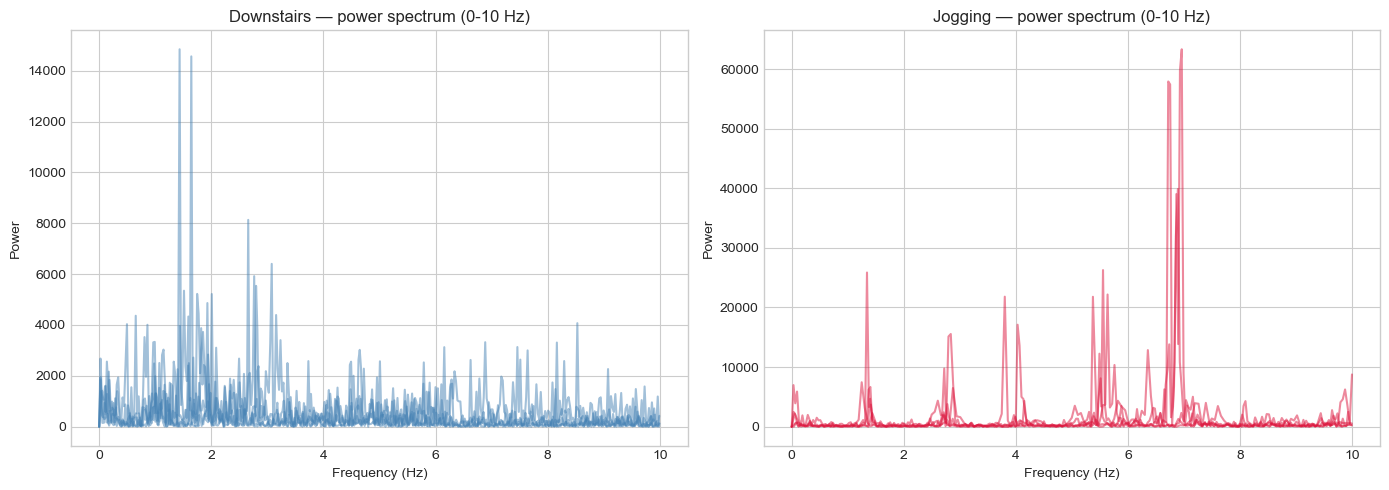

          count      mean       std       min       25%       50%       75%  \
activity                                                                      
dws         5.0  2.424554  1.339640  1.434533  1.440329  1.941748  2.658582   
jog         5.0  5.196020  1.797713  2.875817  3.800217  5.633224  6.714876   

               max  
activity            
dws       4.647577  
jog       6.955967  


In [184]:
from scipy.fft import rfft, rfftfreq

def compute_fft(signal, fs=50.0):
    n = len(signal)
    signal = signal - signal.mean()
    freqs = rfftfreq(n, 1/fs)
    power = np.abs(rfft(signal))**2
    return freqs, power

fig, axes = plt.subplots(1, 2, figsize=(14,5))
fft_rows = []
for activity_prefix, color in [('dws','steelblue'), ('jog','crimson')]:
    for sub in range(1, 6):
        sig = load_raw_signal(activity_prefix, sub)
        if sig is None: continue
        freqs, power = compute_fft(sig)
        mask = freqs < 10
        axes[0 if activity_prefix=='dws' else 1].plot(freqs[mask], power[mask], alpha=0.5, color=color)
        dominant_freq = freqs[mask][np.argmax(power[mask])]
        fft_rows.append({'activity': activity_prefix, 'subject': sub, 'dominant_freq_hz': dominant_freq,
                          'spectral_energy': power[mask].sum()})
axes[0].set_title('Downstairs — power spectrum (0-10 Hz)')
axes[1].set_title('Jogging — power spectrum (0-10 Hz)')
for ax in axes: ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('Power')
plt.tight_layout()
plt.show()

fft_df = pd.DataFrame(fft_rows)
print(fft_df.groupby('activity')['dominant_freq_hz'].describe())

Frequency Analysis Summary

The FFT converts the IMU acceleration signal from the time domain into frequency domain to identify dominant movement frequencies.

Downstairs walking: Energy is concentrated mostly at lower frequencies with a dominant frequency around 1–2 Hz.
Jogging: Shows stronger and more distinct frequency peaks, particularly around 6–7 Hz, indicating faster and more repetitive movement.
Jogging also has substantially higher spectral power, reflecting greater movement intensity.
The dominant frequency differs clearly between activities, making it a useful way to distinguish movement patterns.

Useful derived features

- Dominant_Frequency
- Peak_Frequency
- Spectral_Power
- Spectral_Energy
- Frequency_Band_Energy
- Spectral_Centroid
- Frequency_Band_Ratio

Overall: FFT provides information that mean acceleration cannot capture. Combining time-domain features such as acceleration and cadence with frequency-domain features such as dominant frequency and spectral energy could give a much richer representation of wearable movement.

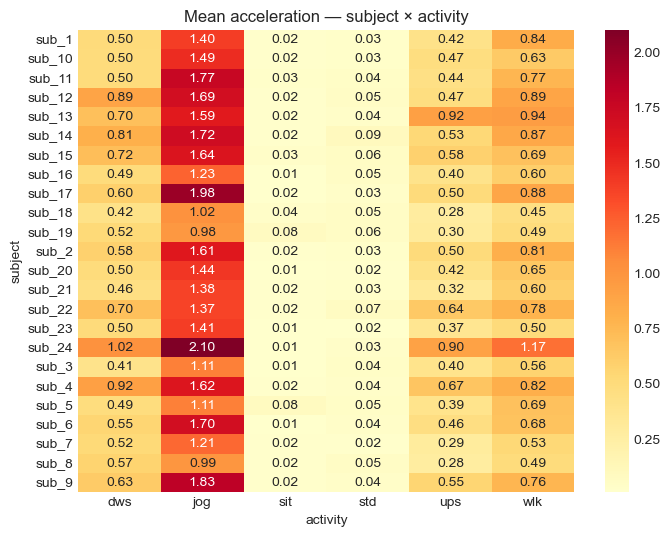

In [190]:
pivot = imu_summary.pivot_table(index='subject', columns='activity', values='acc_mean', aggfunc='mean')
plt.figure(figsize=(8,6))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Mean acceleration — subject × activity')
plt.show()

There is clear variation between subjects for the same activity.
Jogging consistently has the highest mean acceleration across subjects.
Sitting and standing have extremely low acceleration as expected.
Walking shows moderate acceleration while upstairs/downstairs fall between stationary and jogging activities.
Some subjects have noticeably higher acceleration for the same activity, showing individual differences in movement intensity.

Overall: Mean acceleration is strongly activity-dependent but also subject-dependent. This suggests that subject-level normalization or features such as acceleration relative to an individual's baseline could improve modelling

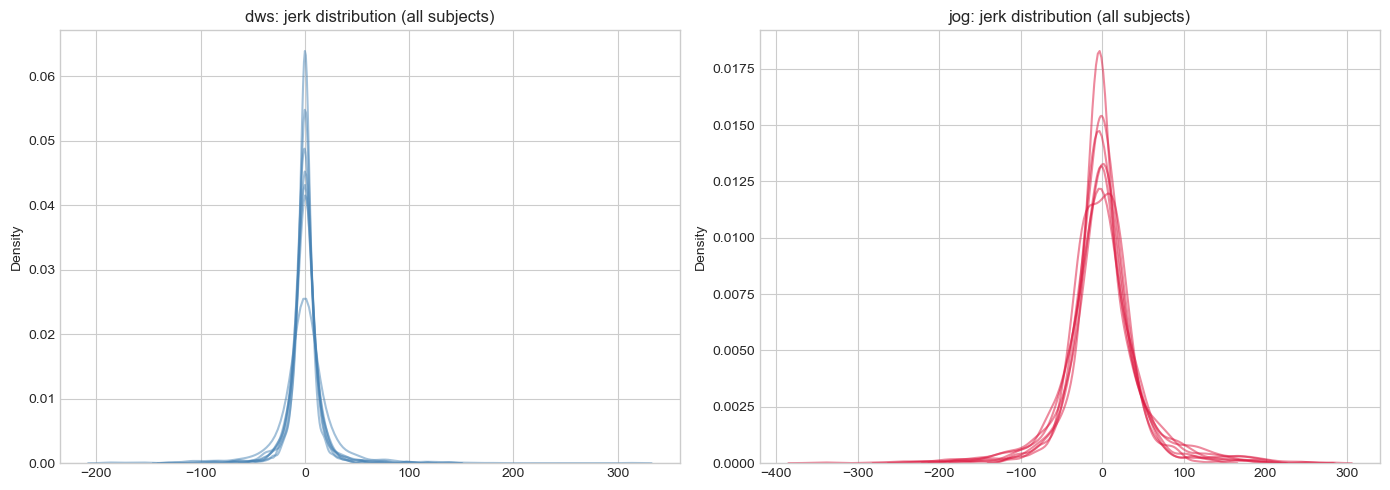

           jerk_std  jerk_max_abs
activity                         
dws       16.371778    144.875662
jog       42.471249    232.594232


In [193]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
jerk_summary = []
for activity_prefix, ax, color in [('dws', axes[0], 'steelblue'), ('jog', axes[1], 'crimson')]:
    for sub in range(1, 8):
        sig = load_raw_signal(activity_prefix, sub)
        if sig is None: continue
        jerk = np.diff(sig) * 50.0  # d(accel)/dt at 50Hz
        sns.kdeplot(jerk, ax=ax, alpha=0.5, color=color, label=f'sub_{sub}' if sub==1 else None)
        jerk_summary.append({'activity': activity_prefix, 'subject': sub, 'jerk_std': jerk.std(), 'jerk_max_abs': np.abs(jerk).max()})
    ax.set_title(f'{activity_prefix}: jerk distribution (all subjects)')
plt.tight_layout()
plt.show()

jerk_df = pd.DataFrame(jerk_summary)
print(jerk_df.groupby('activity')[['jerk_std','jerk_max_abs']].mean())

Jerk measures how quickly acceleration changes over time, so it captures sudden changes or abrupt movements.

Downstairs (dws) has much lower jerk variability: jerk_std ≈ 16.4
Jogging (jog) has much higher variability: jerk_std ≈ 42.5
Maximum jerk is also much higher during jogging: approximately 232.6 compared with 144.9 for downstairs walking.
The jogging distributions are broader, indicating more sudden acceleration changes across subjects.
Overall takeaway

Jerk is a useful feature for capturing movement intensity and abruptness. In an injury-risk context, useful derived features include:

- Jerk_STD
- Maximum_Jerk
- Mean_Absolute_Jerk
- Jerk_Peak_Count
- Jerk_Variability

Overall: Jogging produces substantially more abrupt acceleration changes than walking, making jerk-based features valuable additions to the IMU feature set.

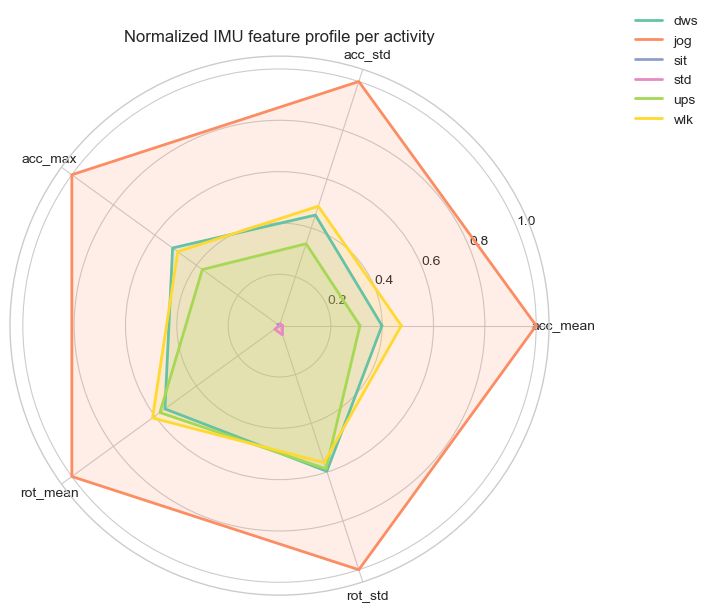

In [195]:
from math import pi

radar_feats = ['acc_mean','acc_std','acc_max','rot_mean','rot_std']
radar_data = imu_summary.groupby('activity')[radar_feats].mean()
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())

angles = [n / len(radar_feats) * 2 * pi for n in range(len(radar_feats))]
angles += angles[:1]

plt.figure(figsize=(7,7))
ax = plt.subplot(111, polar=True)
for activity, color in zip(radar_norm.index, sns.color_palette('Set2', len(radar_norm))):
    values = radar_norm.loc[activity].tolist()
    values += values[:1]
    ax.plot(angles, values, label=activity, color=color, linewidth=2)
    ax.fill(angles, values, color=color, alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_feats)
ax.set_title('Normalized IMU feature profile per activity')
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

The radar chart compares mean acceleration, acceleration variability, maximum acceleration, rotation magnitude and rotation variability across activities.

Jogging clearly has the highest values across almost every feature, indicating the greatest movement intensity and variability.
Walking, upstairs and downstairs have moderate and relatively similar profiles.
Sitting and standing have very low values across all IMU features.
acc_mean, acc_std, acc_max, rot_mean and rot_std together provide a strong activity signature.

Overall: IMU features can effectively distinguish stationary, walking and high-intensity activities. For injury modelling, combining these into a movement intensity/load profile could be more informative than using individual IMU measurements.

## 3. Feature Engineering & Multi-Dataset Fusion
We will build a modular processing script that engineers features from raw sensors, aggregates wearable telemetry, computes acute-to-chronic workload ratios (ACWR), monotony, and strain, and merges them into unified datasets for modeling.


In [199]:
import os
import numpy as np
import pandas as pd
import glob
from scipy.signal import butter, filtfilt, find_peaks
from scipy.fft import rfft, rfftfreq

In [201]:
def extract_imu_features_from_file(file_path, fs=50.0, cutoff=3.0):
    default = {'IMU_Cadence': 0, 'IMU_Peak_Impact': 0, 'IMU_SMA': 0, 'IMU_Acc_Variance': 0,
               'IMU_Rot_Variance': 0, 'IMU_Jerk_Std': 0, 'IMU_Jerk_Max_Abs': 0,
               'IMU_Dominant_Freq': 0, 'IMU_Spectral_Energy': 0}
    try:
        df = pd.read_csv(file_path)
        acc_mag = np.sqrt(df['userAcceleration.x']**2 + df['userAcceleration.y']**2 + df['userAcceleration.z']**2)
        rot_mag = np.sqrt(df['rotationRate.x']**2 + df['rotationRate.y']**2 + df['rotationRate.z']**2)

        b, a = butter(4, cutoff / (0.5 * fs), btype='low')
        filtered_acc = filtfilt(b, a, acc_mag)
        peaks, _ = find_peaks(filtered_acc, distance=15, prominence=0.2)
        total_time = len(df) / fs

        jerk = np.diff(acc_mag.values) * fs
        centered = acc_mag.values - acc_mag.values.mean()
        freqs = rfftfreq(len(centered), 1/fs)
        power = np.abs(rfft(centered))**2
        mask = freqs < 10

        return {
            'IMU_Cadence': (len(peaks) / total_time) * 60 if total_time > 0 else 0,
            'IMU_Peak_Impact': acc_mag.max(),
            'IMU_SMA': np.sum(np.abs(df['userAcceleration.x']) + np.abs(df['userAcceleration.y']) + np.abs(df['userAcceleration.z'])) / len(df),
            'IMU_Acc_Variance': acc_mag.var(),
            'IMU_Rot_Variance': rot_mag.var(),
            'IMU_Jerk_Std': jerk.std(),
            'IMU_Jerk_Max_Abs': np.abs(jerk).max(),
            'IMU_Dominant_Freq': freqs[mask][np.argmax(power[mask])] if mask.sum() > 0 else 0,
            'IMU_Spectral_Energy': power[mask].sum()
        }
    except Exception:
        return default

imu_subjects = []
folders = ['dws_1', 'dws_11', 'dws_2', 'jog_9', 'jog_16']
for sub_idx in range(1, 11):
    sub_features = []
    for folder in folders:
        file_path = f'data/A_DeviceMotion_data/{folder}/sub_{sub_idx}.csv'
        if os.path.exists(file_path):
            sub_features.append(extract_imu_features_from_file(file_path))
    avg_feat = pd.DataFrame(sub_features).mean().to_dict() if sub_features else {
        'IMU_Cadence': 0, 'IMU_Peak_Impact': 0, 'IMU_SMA': 0, 'IMU_Acc_Variance': 0, 'IMU_Rot_Variance': 0,
        'IMU_Jerk_Std': 0, 'IMU_Jerk_Max_Abs': 0, 'IMU_Dominant_Freq': 0, 'IMU_Spectral_Energy': 0}
    avg_feat['Athlete_ID'] = f'A{sub_idx:03d}'
    imu_subjects.append(avg_feat)

imu_features_df = pd.DataFrame(imu_subjects)
print('IMU features extracted:', imu_features_df.shape)

IMU features extracted: (10, 10)


In [203]:
wearable_df['Clean_Athlete_ID'] = wearable_df['Athlete_ID'].str.replace('ATH', 'A')
wearable_agg = wearable_df.groupby('Clean_Athlete_ID').agg(
    Mean_HR=('Heart_Rate', 'mean'),
    Std_HR=('Heart_Rate', 'std'),
    Mean_Temp=('Body_Temperature', 'mean'),
    Mean_Oxygen=('Blood_Oxygen', 'mean'),
    Total_Steps=('Step_Count', 'sum')
).reset_index().rename(columns={'Clean_Athlete_ID': 'Athlete_ID'})

print('Wearable aggregation:', wearable_agg.shape, '| covers', wearable_agg.shape[0], 'of', collegiate_df['Athlete_ID'].nunique(), 'collegiate athletes')

Wearable aggregation: (10, 6) | covers 10 of 200 collegiate athletes


In [205]:
# Workload
collegiate_df['Weekly_Load'] = collegiate_df['Training_Hours_Per_Week'] * collegiate_df['Training_Intensity']
collegiate_df['Estimated_Chronic_Load'] = collegiate_df['Weekly_Load'] * (1.2 - collegiate_df['Fatigue_Score'] * 0.05)
collegiate_df['ACWR'] = collegiate_df['Weekly_Load'] / collegiate_df['Estimated_Chronic_Load']
collegiate_df['Monotony'] = collegiate_df['Weekly_Load'] / (collegiate_df['Load_Balance_Score'].std() * 0.1 + 1)
collegiate_df['Strain'] = collegiate_df['Weekly_Load'] * collegiate_df['Monotony']
collegiate_df['Match_Load'] = collegiate_df['Match_Count_Per_Week'] * collegiate_df['Training_Intensity']
collegiate_df['Training_to_Match_Load_Ratio'] = collegiate_df['Weekly_Load'] / (collegiate_df['Match_Load'] + 1)

# Recovery / fatigue
collegiate_df['Recovery_Deficit'] = collegiate_df['Fatigue_Score'] / (collegiate_df['Recovery_Days_Per_Week'] + 1)
collegiate_df['Workload_to_Recovery_Ratio'] = collegiate_df['Weekly_Load'] / (collegiate_df['Recovery_Days_Per_Week'] + 1)
collegiate_df['Fatigue_Load_Ratio'] = collegiate_df['Fatigue_Score'] / (collegiate_df['Weekly_Load'] + 1)

# Performance
collegiate_df['Performance_per_Workload'] = collegiate_df['Performance_Score'] / (collegiate_df['Weekly_Load'] + 1)

# Fuse wearable + IMU
collegiate_fused = pd.merge(collegiate_df, wearable_agg, on='Athlete_ID', how='left')
collegiate_fused = pd.merge(collegiate_fused, imu_features_df, on='Athlete_ID', how='left')

impute_cols = ['Mean_HR', 'Std_HR', 'Mean_Temp', 'Mean_Oxygen', 'Total_Steps', 'IMU_Cadence', 'IMU_Peak_Impact',
               'IMU_SMA', 'IMU_Acc_Variance', 'IMU_Rot_Variance', 'IMU_Jerk_Std', 'IMU_Jerk_Max_Abs',
               'IMU_Dominant_Freq', 'IMU_Spectral_Energy']
for col in impute_cols:
    collegiate_fused[col] = collegiate_fused[col].fillna(collegiate_fused[col].mean())

# Wearable-derived
collegiate_fused['Heart_Rate_Intensity'] = collegiate_fused['Mean_HR'] / collegiate_fused['Mean_HR'].mean()
collegiate_fused['Heart_Rate_Variability'] = collegiate_fused['Std_HR'] / (collegiate_fused['Mean_HR'] + 1)
collegiate_fused['Steps_to_Heart_Rate_Ratio'] = collegiate_fused['Total_Steps'] / (collegiate_fused['Mean_HR'] + 1)
collegiate_fused['Body_Temperature_Deviation'] = collegiate_fused['Mean_Temp'] - collegiate_fused['Mean_Temp'].mean()

# IMU-derived
collegiate_fused['Movement_Intensity'] = collegiate_fused['IMU_SMA'] * collegiate_fused['IMU_Cadence']
collegiate_fused['Combined_Motion_Intensity'] = collegiate_fused['IMU_Acc_Variance'] + collegiate_fused['IMU_Rot_Variance']
collegiate_fused['Acceleration_Rotation_Ratio'] = collegiate_fused['IMU_Acc_Variance'] / (collegiate_fused['IMU_Rot_Variance'] + 1e-6)
collegiate_fused['Subject_Normalized_Acceleration'] = (
    (collegiate_fused['IMU_Peak_Impact'] - collegiate_fused['IMU_Peak_Impact'].mean()) / collegiate_fused['IMU_Peak_Impact'].std()
)

print('collegiate_fused final shape:', collegiate_fused.shape)
print('ACL_Risk_Score correlation with target (verify not leakage before using as feature):',
      collegiate_fused[['ACL_Risk_Score','Injury_Indicator']].corr().iloc[0,1])

collegiate_fused final shape: (200, 50)
ACL_Risk_Score correlation with target (verify not leakage before using as feature): 0.5251799569006672


In [207]:
physical_cols = ['Knee_Strength_Score', 'Hamstring_Flexibility', 'Balance_Test_Score', 'Sprint_Speed_10m_s', 'Agility_Score']
physical_z = university_df[physical_cols].apply(lambda s: (s - s.mean()) / s.std())
university_df['Overall_Physical_Readiness'] = physical_z.mean(axis=1)

university_df['Strength_Flexibility_Ratio'] = university_df['Knee_Strength_Score'] / (university_df['Hamstring_Flexibility'] + 1)
university_df['Strength_Deficit'] = university_df['Knee_Strength_Score'].mean() - university_df['Knee_Strength_Score']
university_df['Balance_Deficit'] = university_df['Balance_Test_Score'].mean() - university_df['Balance_Test_Score']
university_df['Agility_Deficit'] = university_df['Agility_Score'].mean() - university_df['Agility_Score']
university_df['Reaction_Time_Normalized'] = (
    (university_df['Reaction_Time_ms'] - university_df['Reaction_Time_ms'].mean()) / university_df['Reaction_Time_ms'].std()
)

university_df['Sleep_Deficit'] = 8 - university_df['Sleep_Hours_Per_Night']
lifestyle_cols = ['Sleep_Hours_Per_Night', 'Stress_Level_Score', 'Nutrition_Quality_Score']
university_df['Recovery_Consistency'] = university_df[lifestyle_cols].apply(lambda s: (s - s.mean()) / s.std()).std(axis=1)

university_df['Minutes_Per_Game'] = (university_df['Training_Hours_Per_Week'] * 60) / (university_df['Matches_Played_Past_Season'] + 1)
university_df['Injury_Frequency'] = university_df['Previous_Injury_Count'] / (university_df['Matches_Played_Past_Season'] + 1)

# BMI redundancy — keep BMI, drop the two raw columns it's derived from
university_df = university_df.drop(columns=['Height_cm', 'Weight_kg'])

print('university_df final shape:', university_df.shape)

university_df final shape: (800, 27)


In [209]:
football_df['first_season_seen'] = football_df.groupby('p_id2')['start_year'].transform('min')
football_df['is_first_observed_season'] = (football_df['start_year'] == football_df['first_season_seen']).astype(int)
football_df['has_prior_history'] = football_df['cumulative_minutes_played'].notna().astype(int)

football_df['Minutes_Per_Game'] = football_df['season_minutes_played'] / (football_df['season_games_played'] + 1)
football_df['Cumulative_Workload'] = football_df['cumulative_minutes_played'].fillna(0) + football_df['season_minutes_played']
football_df['Injury_Burden'] = football_df['total_days_injured'] / (football_df['total_games_played'] + 1)

# Lagged injury history — filled with 0, not median (these are MNAR: missing means "no history yet", not "average history")
football_df['Injury_Persistence'] = football_df['season_days_injured_prev_season'].fillna(0)
football_df['Previous_Injury_Severity'] = football_df['avg_days_injured_prev_seasons'].fillna(0)
football_df['Recent_Injury_Burden'] = football_df['significant_injury_prev_season'].fillna(0)
football_df['Performance_Decline'] = football_df['minutes_per_game_prev_seasons'].fillna(0) - football_df['Minutes_Per_Game']

# work_rate: split the compound string instead of using the lossy pre-collapsed numeric code
wr_split = football_df['work_rate'].str.split('/', expand=True)
wr_map = {'Low': 1, 'Medium': 2, 'High': 3}
football_df['Attack_Work_Rate'] = wr_split[0].map(wr_map)
football_df['Defense_Work_Rate'] = wr_split[1].map(wr_map)

print('football_df final shape:', football_df.shape)
print('% rows with has_prior_history == 0:', (football_df['has_prior_history']==0).mean()*100)

football_df final shape: (1301, 42)
% rows with has_prior_history == 0: 46.425826287471175


## 4. Model A: Next-Season Injury Risk Classification
We train classifiers on the balanced `university_df` dataset containing demographic, physical screening, and lifestyle features to predict next-season injuries. We optimize hyper-parameters using Optuna.


In [213]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Prepare features and target
X_uni = university_df.drop(columns=['Injury_Next_Season', 'Position'])
y_uni = university_df['Injury_Next_Season']

# Check for any NaNs introduced by the new ratio/deficit features before proceeding
nan_check = X_uni.isnull().sum()
if nan_check.sum() > 0:
    print("NaNs found in engineered features — filling with column median:")
    print(nan_check[nan_check > 0])
    X_uni = X_uni.fillna(X_uni.median())

def compute_vif(df):
    vif_data = pd.DataFrame()
    vif_data['feature'] = df.columns
    vif_data['VIF'] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return vif_data.sort_values('VIF', ascending=False)

vif_before = compute_vif(X_uni)
print("VIF — features above 10 are strong multicollinearity candidates:")
print(vif_before.head(15))

# Drop features with VIF > 10, keeping the composite index over its raw components
# (Overall_Physical_Readiness summarizes Knee_Strength/Hamstring_Flex/Balance/Sprint/Agility —
#  those raw deficit/raw scores are the expected redundant ones to drop here)
high_vif_features = vif_before[vif_before['VIF'] > 10]['feature'].tolist()
high_vif_features = [f for f in high_vif_features if f != 'Overall_Physical_Readiness']  # protect the composite
print(f"\nDropping high-VIF raw components: {high_vif_features}")
X_uni = X_uni.drop(columns=high_vif_features, errors='ignore')

vif_after = compute_vif(X_uni)
print("\nVIF after pruning:")
print(vif_after)

VIF — features above 10 are strong multicollinearity candidates:
                       feature        VIF
10       Sleep_Hours_Per_Night        inf
8           Sprint_Speed_10m_s        inf
18             Balance_Deficit        inf
17            Strength_Deficit        inf
15  Overall_Physical_Readiness        inf
21               Sleep_Deficit        inf
20    Reaction_Time_Normalized        inf
9                Agility_Score        inf
19             Agility_Deficit        inf
7           Balance_Test_Score        inf
6             Reaction_Time_ms        inf
5        Hamstring_Flexibility        inf
4          Knee_Strength_Score        inf
16  Strength_Flexibility_Ratio  94.862821
23            Minutes_Per_Game   5.154508

Dropping high-VIF raw components: ['Sleep_Hours_Per_Night', 'Sprint_Speed_10m_s', 'Balance_Deficit', 'Strength_Deficit', 'Sleep_Deficit', 'Reaction_Time_Normalized', 'Agility_Score', 'Agility_Deficit', 'Balance_Test_Score', 'Reaction_Time_ms', 'Hamstring_Flexibi

In [215]:
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_uni, y_uni, test_size=0.2, random_state=42, stratify=y_uni
)

scaler_u = StandardScaler()
X_train_u_scaled = scaler_u.fit_transform(X_train_u)
X_test_u_scaled = scaler_u.transform(X_test_u)

print(f'Train size: {X_train_u_scaled.shape[0]} | Test size: {X_test_u_scaled.shape[0]} | Features: {X_uni.shape[1]}')

Train size: 640 | Test size: 160 | Features: 12


### Optuna Hyperparameter Optimization - Model A (LightGBM)


In [217]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_a(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves': trial.suggest_int('num_leaves', 10, 50),
        'verbose': -1,
        'random_state': 42
    }
    clf = lgb.LGBMClassifier(**params)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for train_idx, val_idx in cv.split(X_train_u_scaled, y_train_u):
        X_tr, X_val = X_train_u_scaled[train_idx], X_train_u_scaled[val_idx]
        y_tr, y_val = y_train_u.iloc[train_idx], y_train_u.iloc[val_idx]
        clf.fit(X_tr, y_tr)
        scores.append(roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1]))
    return np.mean(scores)

study_a = optuna.create_study(direction='maximize')
study_a.optimize(objective_a, n_trials=10)
print('Best trial parameters:', study_a.best_params)
print(f'Best cross-validation ROC-AUC: {study_a.best_value:.4f}')

  File "C:\Users\hp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\hp\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Best trial parameters: {'n_estimators': 142, 'max_depth': 6, 'learning_rate': 0.028375376126075512, 'num_leaves': 12}
Best cross-validation ROC-AUC: 0.9699


### Evaluate Models on Next-Season Injury Risk


In [219]:
best_params_a = study_a.best_params
best_params_a['verbose'] = -1
best_params_a['random_state'] = 42

models_a = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM (Tuned)': lgb.LGBMClassifier(**best_params_a)
}

results_a = {}
for name, model in models_a.items():
    model.fit(X_train_u_scaled, y_train_u)
    preds = model.predict(X_test_u_scaled)
    probs = model.predict_proba(X_test_u_scaled)[:, 1] if hasattr(model, 'predict_proba') else preds
    roc_auc = roc_auc_score(y_test_u, probs)
    results_a[name] = {'model': model, 'preds': preds, 'probs': probs, 'roc_auc': roc_auc}
    print(f'{name} Test ROC-AUC: {roc_auc:.4f}')

best_model_name = max(results_a, key=lambda k: results_a[k]['roc_auc'])
best_model_res = results_a[best_model_name]
print(f'\n--- Final Classification Report for Best Model: {best_model_name} ---')
print(classification_report(y_test_u, best_model_res['preds']))

# New: feature importance from the winning model, if tree-based, to confirm the engineered features earn their place
if hasattr(best_model_res['model'], 'feature_importances_'):
    importances = pd.Series(best_model_res['model'].feature_importances_, index=X_uni.columns).sort_values(ascending=False)
    print(f"\nTop 15 features by importance ({best_model_name}):")
    print(importances.head(15))

Logistic Regression Test ROC-AUC: 0.9808
Random Forest Test ROC-AUC: 0.9815
XGBoost Test ROC-AUC: 0.9762
LightGBM (Tuned) Test ROC-AUC: 0.9792

--- Final Classification Report for Best Model: Random Forest ---
              precision    recall  f1-score   support

           0       0.94      0.91      0.92        80
           1       0.91      0.94      0.93        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.92       160
weighted avg       0.93      0.93      0.92       160


Top 15 features by importance (Random Forest):
Overall_Physical_Readiness    0.418942
Stress_Level_Score            0.178427
Nutrition_Quality_Score       0.101243
Injury_Frequency              0.057930
Recovery_Consistency          0.048459
Previous_Injury_Count         0.041197
Training_Hours_Per_Week       0.033972
BMI                           0.031549
Minutes_Per_Game              0.028064
Matches_Played_Past_Season    0.026181
Warmup_Routine_Adherence 

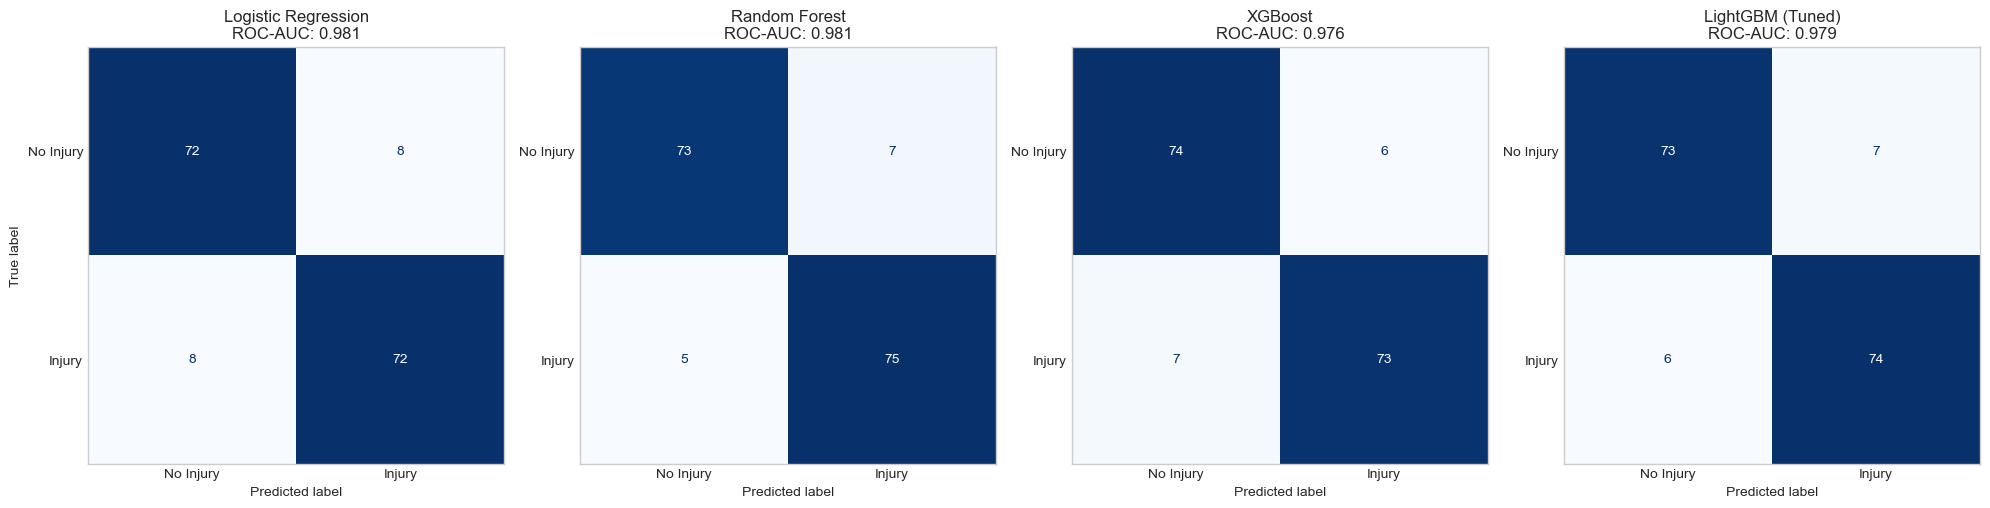

In [223]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, res) in zip(axes, results_a.items()):
    cm = confusion_matrix(y_test_u, res['preds'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Injury', 'Injury'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.grid(False)                      # kills the leftover whitegrid lines
    ax.set_title(f"{name}\nROC-AUC: {res['roc_auc']:.3f}")
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label' if ax is axes[0] else '')
plt.tight_layout()
plt.show()

## 5. Model B: Acute Injury Risk Classification (Highly Imbalanced)
We train models on the highly imbalanced `collegiate_fused` dataset (7% injury rate). We apply SMOTE to the training set, tune model hyper-parameters via Optuna, apply Platt Scaling probability calibration, and optimize classification thresholds to minimize missed risk flags (False Negatives).


In [249]:
# Full feature set — no VIF pruning, used for ALL models including Logistic Regression
X_col_full = collegiate_fused.drop(columns=['Athlete_ID', 'Gender', 'Position', 'Injury_Indicator'])
X_col_full = X_col_full.fillna(X_col_full.median())

y_col = collegiate_fused['Injury_Indicator']

print(f"Feature set: {X_col_full.shape[1]} features (no pruning)")

# Leakage check — keep this regardless
leak_corr = collegiate_fused[['ACL_Risk_Score', 'Injury_Indicator']].corr().iloc[0,1]
print(f"ACL_Risk_Score correlation with Injury_Indicator: {leak_corr:.3f}")

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_col_full, y_col, test_size=0.2, random_state=42, stratify=y_col
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_c_res, y_train_c_res = smote.fit_resample(X_train_c_scaled, y_train_c)

print(f'Original Train target counts: {np.bincount(y_train_c)}')
print(f'Resampled Train target counts: {np.bincount(y_train_c_res)}')
print(f'Test set positive count: {y_test_c.sum()} / {len(y_test_c)}')

Feature set: 46 features (no pruning)
ACL_Risk_Score correlation with Injury_Indicator: 0.525
Original Train target counts: [149  11]
Resampled Train target counts: [149 149]
Test set positive count: 3 / 40


### Optuna Hyperparameter Optimization - Model B (XGBoost)


In [251]:
def objective_b(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 150),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'random_state': 42,
        'eval_metric': 'logloss'
    }
    clf = xgb.XGBClassifier(**params)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for train_idx, val_idx in cv.split(X_train_c_res, y_train_c_res):
        X_tr, X_val = X_train_c_res[train_idx], X_train_c_res[val_idx]
        y_tr, y_val = y_train_c_res[train_idx], y_train_c_res[val_idx]
        clf.fit(X_tr, y_tr)
        scores.append(roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1]))
    return np.mean(scores)

study_b = optuna.create_study(direction='maximize')
study_b.optimize(objective_b, n_trials=10)
print('Best trial parameters:', study_b.best_params)
print(f'Best cross-validation ROC-AUC: {study_b.best_value:.4f}')

Best trial parameters: {'n_estimators': 95, 'max_depth': 4, 'learning_rate': 0.04296917363797429, 'subsample': 0.746615483302189}
Best cross-validation ROC-AUC: 0.9986


### Evaluate & Calibrate Models on Acute Risk


In [253]:
best_params_b = study_b.best_params
best_params_b['eval_metric'] = 'logloss'
best_params_b['random_state'] = 42

base_xgb = xgb.XGBClassifier(**best_params_b)
calibrated_xgb = CalibratedClassifierCV(estimator=base_xgb, method='sigmoid', cv=5)
calibrated_xgb.fit(X_train_c_res, y_train_c_res)

models_b = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost (Tuned)': xgb.XGBClassifier(**best_params_b),
    'Calibrated XGBoost (Tuned)': calibrated_xgb
}

results_b = {}
for name, model in models_b.items():
    if name == 'Calibrated XGBoost (Tuned)':
        pass  # already fitted
    else:
        model.fit(X_train_c_res, y_train_c_res)

    preds = model.predict(X_test_c_scaled)
    probs = model.predict_proba(X_test_c_scaled)[:, 1]
    roc_auc = roc_auc_score(y_test_c, probs)
    results_b[name] = {'model': model, 'preds': preds, 'probs': probs, 'roc_auc': roc_auc}
    print(f'{name} Test ROC-AUC: {roc_auc:.4f}')

Logistic Regression Test ROC-AUC: 0.9550
Random Forest Test ROC-AUC: 0.9820
XGBoost (Tuned) Test ROC-AUC: 0.9820
Calibrated XGBoost (Tuned) Test ROC-AUC: 0.9820


### 5.3 Classification Threshold Optimization
In sports science, missing a high-risk injury flag (False Negative) is much costlier than generating a false alarm (False Positive). We compute the Precision-Recall Curve on our best calibrated model and select an optimal classification threshold that optimizes F1-score and preserves high Recall (sensitivity).


Test set positives: 3 / 40 — threshold selection below is based on very few positive cases; treat as directional.
F1-optimal threshold: 0.8044
F2-optimal threshold (recall-weighted): 0.8044

--- F1-optimal threshold = 0.8044 ---
[[37  0]
 [ 0  3]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       1.00      1.00      1.00         3

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


--- F2-optimal (recommended) threshold = 0.8044 ---
[[37  0]
 [ 0  3]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       1.00      1.00      1.00         3

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



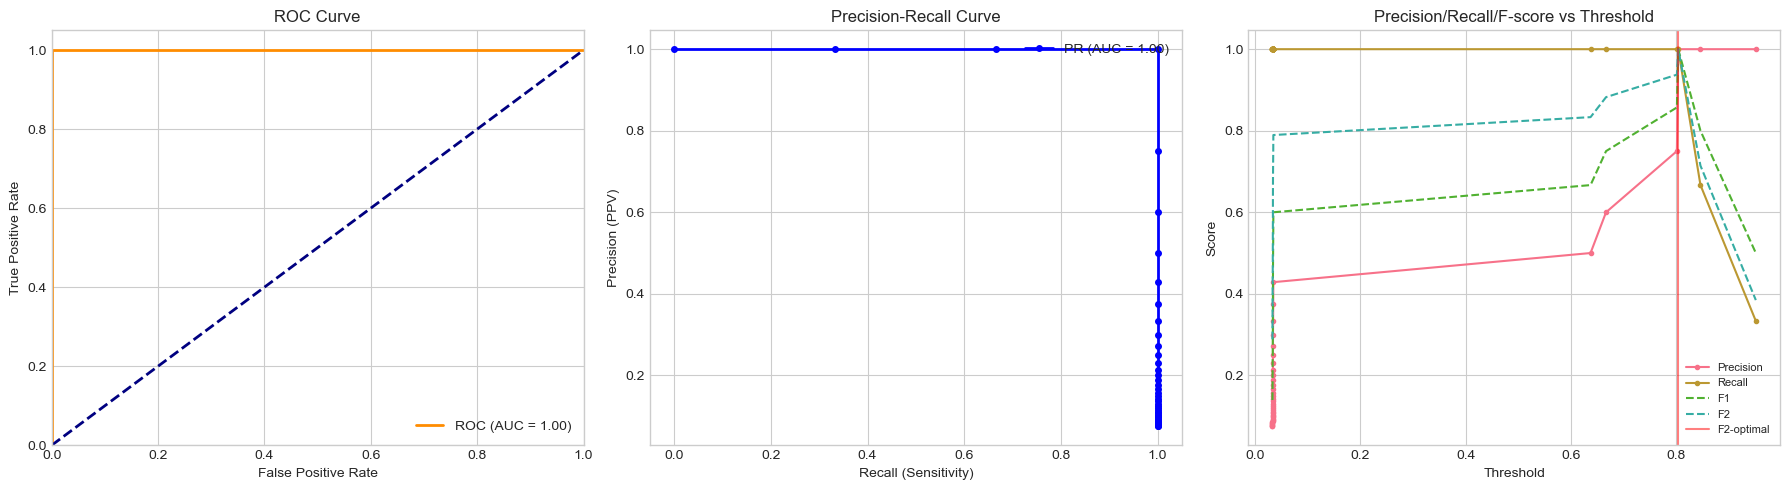

In [233]:
best_model_res = results_b['Calibrated XGBoost (Tuned)']
probs = best_model_res['probs']

print(f"Test set positives: {y_test_c.sum()} / {len(y_test_c)} — threshold selection below is based on very few positive cases; treat as directional.")

# ROC and Precision-Recall curves
fpr, tpr, _ = roc_curve(y_test_c, probs)
precision, recall, thresholds = precision_recall_curve(y_test_c, probs)

# F1 (equal weight) and F2 (recall-weighted, matches the cost asymmetry discussed for this model)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
beta = 2
f2_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall + 1e-10)

best_f1_idx = np.argmax(f1_scores)
best_f2_idx = np.argmax(f2_scores)
best_thresh_f1 = thresholds[best_f1_idx] if best_f1_idx < len(thresholds) else 0.5
best_thresh_f2 = thresholds[best_f2_idx] if best_f2_idx < len(thresholds) else 0.5

print(f'F1-optimal threshold: {best_thresh_f1:.4f}')
print(f'F2-optimal threshold (recall-weighted): {best_thresh_f2:.4f}')

for label, thresh in [('F1-optimal', best_thresh_f1), ('F2-optimal (recommended)', best_thresh_f2)]:
    custom_preds = (probs >= thresh).astype(int)
    print(f'\n--- {label} threshold = {thresh:.4f} ---')
    print(confusion_matrix(y_test_c, custom_preds))
    print(classification_report(y_test_c, custom_preds))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC curve
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {best_model_res["roc_auc"]:.2f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0]); axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc='lower right')

# PR curve
axes[1].plot(recall, precision, color='blue', lw=2, marker='o', markersize=4, label=f'PR (AUC = {auc(recall, precision):.2f})')
axes[1].set_xlabel('Recall (Sensitivity)'); axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend(loc='upper right')

# Metric vs threshold — shows how few real decision points exist
axes[2].plot(thresholds, precision[:-1], label='Precision', marker='o', markersize=3)
axes[2].plot(thresholds, recall[:-1], label='Recall', marker='o', markersize=3)
axes[2].plot(thresholds, f1_scores[:-1], label='F1', linestyle='--')
axes[2].plot(thresholds, f2_scores[:-1], label='F2', linestyle='--')
axes[2].axvline(best_thresh_f2, color='red', alpha=0.5, label='F2-optimal')
axes[2].set_xlabel('Threshold'); axes[2].set_ylabel('Score')
axes[2].set_title('Precision/Recall/F-score vs Threshold')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 6. Model C: Sidelined Sickness/Injury Duration Regression
We train regression models on `football_df` to predict the continuous target `season_days_injured` based on cumulative workloads and historical injury durations.


Feature count: 34
Unique players: 604 across 1301 rows
Remaining NaNs after fill: 0
Player overlap between train/test: 0 (should be 0)
Random Forest Regressor RMSE: 78.51 days
Random Forest Regressor R2 Score: 0.3238


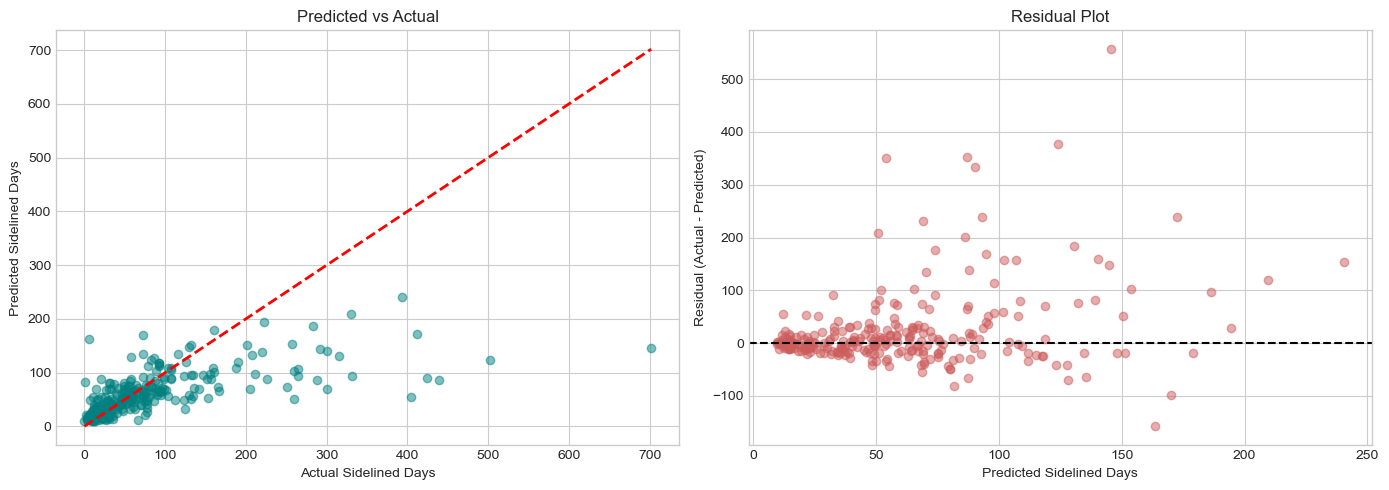

Top 15 features by importance:
season_matches_in_squad    0.314817
Injury_Burden              0.157293
total_minutes_played       0.043568
total_games_played         0.041908
season_minutes_played      0.030039
cumulative_days_injured    0.028483
Minutes_Per_Game           0.027320
pace                       0.026987
season_games_played        0.026731
fifa_rating                0.026608
bmi                        0.026177
age                        0.025051
Performance_Decline        0.023528
physic                     0.023424
Cumulative_Workload        0.020762
dtype: float64


In [235]:
from sklearn.model_selection import GroupShuffleSplit

# Prepare features and target — now includes the engineered columns, drops helper column
drop_cols = ['p_id2', 'dob', 'nationality', 'work_rate', 'position',
             'season_days_injured', 'total_days_injured', 'first_season_seen']
X_foot = football_df.drop(columns=drop_cols, errors='ignore')
y_foot = football_df['season_days_injured']
groups_foot = football_df['p_id2']  # needed for group-aware split, not a feature

print(f"Feature count: {X_foot.shape[1]}")
print(f"Unique players: {groups_foot.nunique()} across {len(football_df)} rows")

# Columns where missingness is structural (rookie season, no history yet) — already 0-filled in feature engineering
prev_season_cols = ['Injury_Persistence', 'Previous_Injury_Severity', 'Recent_Injury_Burden',
                     'cumulative_minutes_played', 'cumulative_games_played', 'Cumulative_Workload']
prev_season_cols = [c for c in prev_season_cols if c in X_foot.columns]

# Everything else (e.g. pace, physic — plain ~7% missing, not history-related) — median-fill is fine here
other_cols = [c for c in X_foot.columns if c not in prev_season_cols]
X_foot[prev_season_cols] = X_foot[prev_season_cols].fillna(0)
X_foot[other_cols] = X_foot[other_cols].fillna(X_foot[other_cols].median())

print("Remaining NaNs after fill:", X_foot.isnull().sum().sum())

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_foot, y_foot, groups=groups_foot))

X_train_f, X_test_f = X_foot.iloc[train_idx], X_foot.iloc[test_idx]
y_train_f, y_test_f = y_foot.iloc[train_idx], y_foot.iloc[test_idx]

# Verify no player appears in both splits
overlap = set(groups_foot.iloc[train_idx]) & set(groups_foot.iloc[test_idx])
print(f"Player overlap between train/test: {len(overlap)} (should be 0)")

scaler_f = StandardScaler()
X_train_f_scaled = scaler_f.fit_transform(X_train_f)
X_test_f_scaled = scaler_f.transform(X_test_f)

y_train_f_log = np.log1p(y_train_f)

regressor = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
regressor.fit(X_train_f_scaled, y_train_f_log)

reg_preds_log = regressor.predict(X_test_f_scaled)
reg_preds = np.expm1(reg_preds_log)          # back to original day-count scale for reporting
reg_preds = np.clip(reg_preds, 0, None)       # days injured can't be negative

rmse = np.sqrt(mean_squared_error(y_test_f, reg_preds))
r2 = r2_score(y_test_f, reg_preds)
print(f'Random Forest Regressor RMSE: {rmse:.2f} days')
print(f'Random Forest Regressor R2 Score: {r2:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_f, reg_preds, alpha=0.5, color='teal')
axes[0].plot([y_test_f.min(), y_test_f.max()], [y_test_f.min(), y_test_f.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Sidelined Days')
axes[0].set_ylabel('Predicted Sidelined Days')
axes[0].set_title('Predicted vs Actual')

residuals = y_test_f - reg_preds
axes[1].scatter(reg_preds, residuals, alpha=0.5, color='indianred')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('Predicted Sidelined Days')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')
plt.tight_layout()
plt.show()

importances = pd.Series(regressor.feature_importances_, index=X_foot.columns).sort_values(ascending=False)
print("Top 15 features by importance:")
print(importances.head(15))

## 7. Model Interpretation (SHAP Explainability)
We calculate SHAP (SHapley Additive exPlanations) values on our calibrated tree ensemble model (Model B) to trace individual risk scores back to physical and physiological drivers.


Shape check — X_train_c: (160, 46), shap_values: (160, 46)


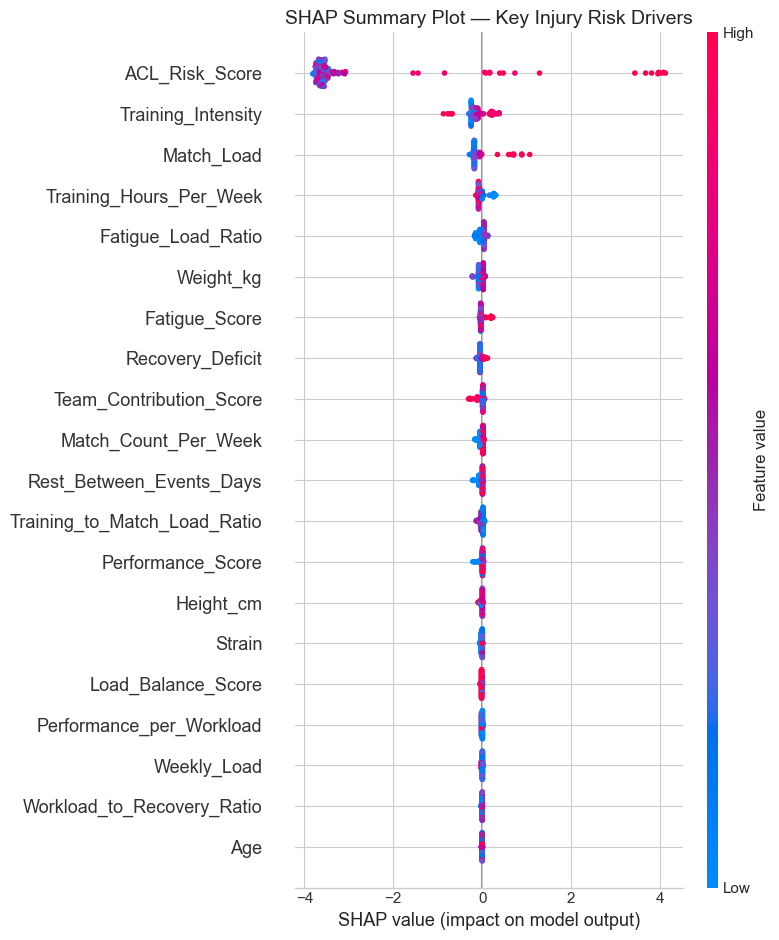

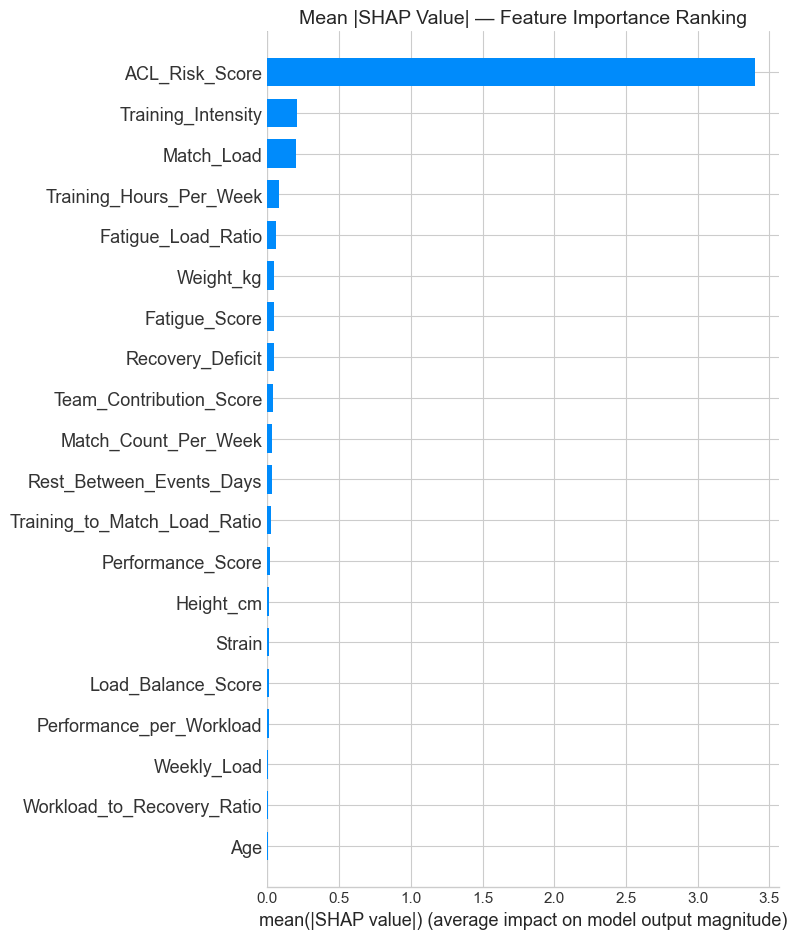

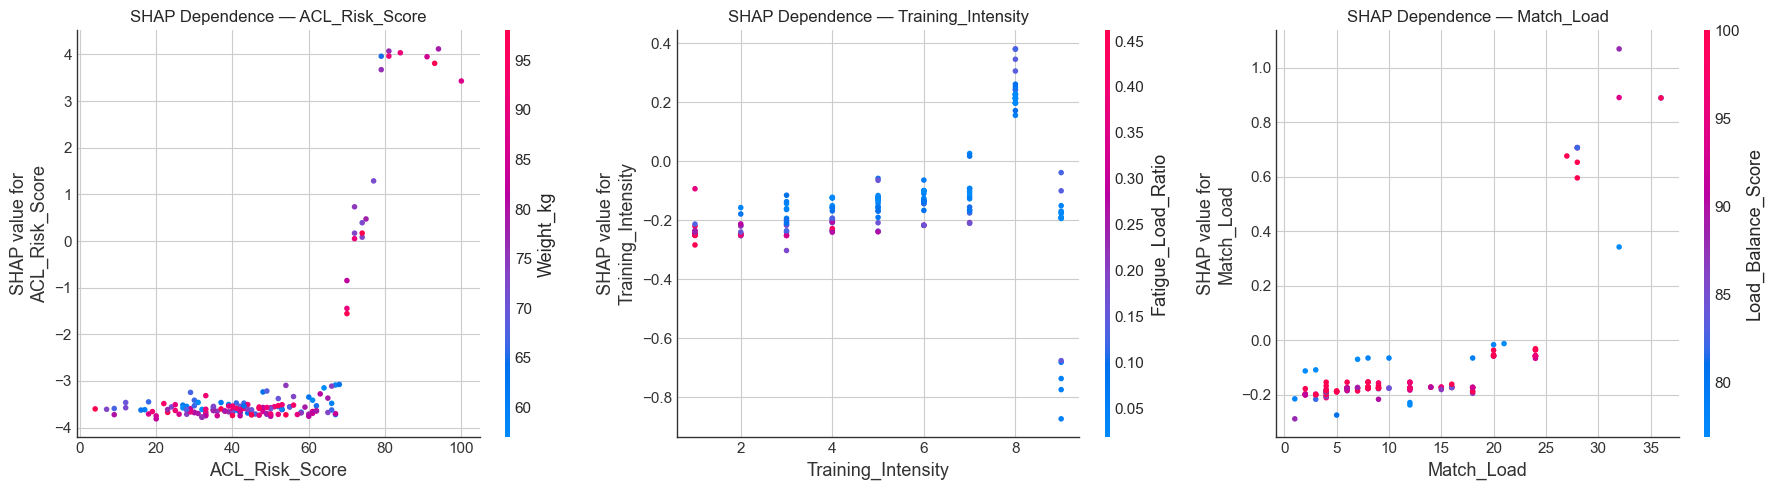

In [257]:
# Use TreeExplainer on the base (uncalibrated) XGBoost model — calibration wraps the model,
# so TreeExplainer needs the raw booster, not calibrated_xgb
explainer = shap.TreeExplainer(models_b['XGBoost (Tuned)'])
shap_values = explainer(X_train_c_scaled)

# Use the UNSCALED training features for display — same rows/order as X_train_c_scaled,
# so SHAP values line up correctly but axis labels show real units (hours, scores, bpm)
# instead of standardized z-scores
print(f"Shape check — X_train_c: {X_train_c.shape}, shap_values: {shap_values.values.shape}")
assert X_train_c.shape[1] == shap_values.values.shape[1], "Column count mismatch — check X_train_c and X_col_full are built from the same feature set"

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_train_c, feature_names=X_col_full.columns.tolist(), show=False)
plt.title('SHAP Summary Plot — Key Injury Risk Drivers', fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, X_train_c, feature_names=X_col_full.columns.tolist(), plot_type='bar', show=False)
plt.title('Mean |SHAP Value| — Feature Importance Ranking', fontsize=14)
plt.tight_layout()
plt.show()

top_features = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_col_full.columns).sort_values(ascending=False).head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, top_features):
    shap.dependence_plot(feat, shap_values.values, X_train_c, feature_names=X_col_full.columns.tolist(), ax=ax, show=False)
    ax.set_title(f'SHAP Dependence — {feat}')
plt.tight_layout()
plt.show()

### Individual Risk Attribution
We visualize the SHAP force attribution for a high-risk athlete to see which specific parameters (such as elevated ACWR or low knee strength) are driving the flag.


Athlete index in test set with highest risk: 39
Predicted injury probability: 94.52%


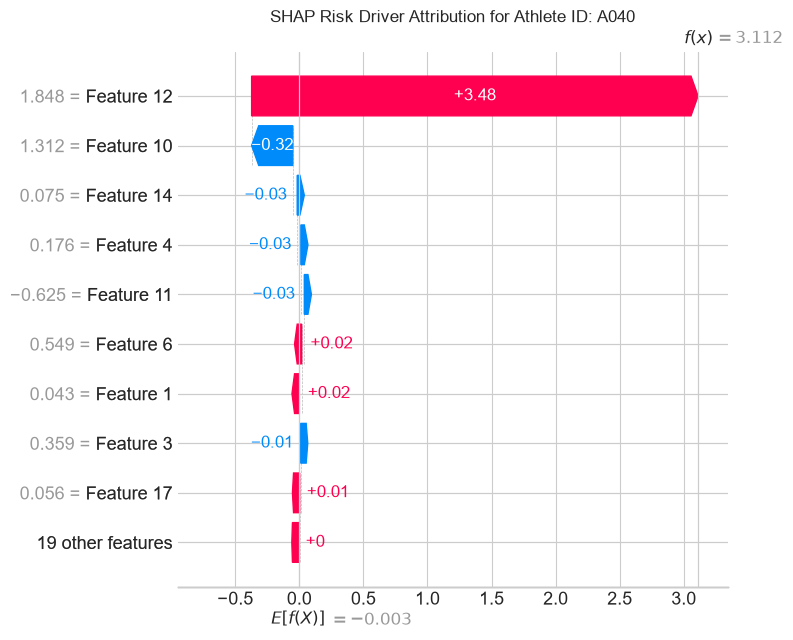

In [18]:
# Find an athlete with high predicted risk in test set
high_risk_idx = np.argmax(probs)
print(f'Athlete index in test set with highest risk: {high_risk_idx}')
print(f'Predicted injury probability: {probs[high_risk_idx]*100:.2f}%')

# Explaining a single prediction using SHAP Waterfall plot
single_explainer = shap.TreeExplainer(models_b['XGBoost (Tuned)'])
single_shap_values = single_explainer(X_test_c_scaled)

plt.figure(figsize=(8, 6))
shap.plots.waterfall(single_shap_values[high_risk_idx], max_display=10, show=False)
plt.title(f'SHAP Risk Driver Attribution for Athlete ID: {collegiate_fused["Athlete_ID"].iloc[high_risk_idx]}', fontsize=12)
plt.tight_layout()
plt.show()


## 8. Edge Deployment & Production Considerations
To deploy AthleteShield in an elite sports setting, we outline key architectural considerations:
- **Edge-First Architecture**: Inference runs on local gateways or on-premises servers (e.g., team wearable hub) to maintain raw biometric data within the team's facility, easing data-governance/HIPAA compliance.
- **Federated Learning**: Retraining models across multiple sport clubs without centralizing raw athlete databases solves both the class-imbalance label-scarcity problem and privacy challenges simultaneously.
- **Human-in-the-Loop Design**: Surfacing traffic-light risk flags (Green/Yellow/Red) and load-management recommendations to clinical/medical staff rather than making autonomous selection decisions.

### Save Final Model Pipeline


In [19]:
# Save trained Model B pipeline components
joblib.dump(calibrated_xgb, 'outputs/best_acute_injury_model.joblib')
joblib.dump(scaler_c, 'outputs/collegiate_scaler.joblib')
print('AthleteShield models saved successfully in outputs/ directory.')


AthleteShield models saved successfully in outputs/ directory.
